<a href="https://colab.research.google.com/github/ASAbuSayem/QMed-Hybrid-Quantum-Machine-Learning-Platform-for-Early-Disease-Detection/blob/main/QMed_Journal_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QMed — Journal Edition V2 (A to Z)
## Hybrid Quantum Machine Learning for Early Disease Detection: a multi-seed, leak-free, statistically tested benchmark

 Md. Abu Sayem · Team Dark-47 · MRIIRS



## ধাপ ০ — Installation
Colab-এ প্রথমবার চালালে এই cell লাগবে। শেষ হলে Runtime restart করার দরকার নেই।

In [1]:
!pip install -q pennylane imbalanced-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 35.2 MB/s eta 0:00:00


## ধাপ ১ — Configuration

সব experimental সেটিং এক জায়গায় রাখা হয়েছে, যাতে paper-এর Methods section-এ হুবহু লেখা যায়।

- `QUICK = True` দিলে কম seed আর কম permutation দিয়ে দ্রুত পুরো notebook test করা যায় (~১০–১৫ মিনিট)।
- **Paper-এর final সংখ্যার জন্য অবশ্যই `QUICK = False`** দিয়ে চালাতে হবে।
- `RUN_VARIATIONAL` VQC আর QNN train করে। এ দুটো ধীর, তাই শুধু primary dataset (Cleveland)-এ চালানো হয়।

In [2]:
import os, time, json, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

QUICK = False           # final paper run; set True for a fast pipeline check
RUN_VARIATIONAL = True  # VQC + QNN on the primary dataset

SEEDS = [0, 1, 2] if QUICK else [0, 1, 2, 3, 4]
N_FOLDS = 5
N_QUBITS = 4
ANGLE_SCALE = np.pi / 4          # encoding bandwidth alpha (fixed a priori)
K_BEST = 10                      # univariate pre-selection before PCA
N_PERMUTATIONS = 30 if QUICK else 200
EQUIV_MARGIN = 0.02              # TOST equivalence margin in ROC-AUC
GAP_FLAG = 0.05                  # train-val AUC gap that triggers an overfitting flag
VAR_EPOCHS = 50 if QUICK else 150
SHOTS_LIST = [64, 256, 1024, 4096]
NOISE_LIST = [0.0, 0.005, 0.01, 0.02, 0.05]
BANDWIDTHS = {"pi/16": np.pi/16, "pi/8": np.pi/8, "pi/4": np.pi/4,
              "pi/2": np.pi/2, "pi": np.pi}

# Plausible honest ROC-AUC ceilings from the literature; values above trigger a leakage check
PLAUSIBLE_AUC_CEILING = {"cleveland": 0.95, "pima": 0.88, "wisconsin": 0.999, "golub": 1.0}

RESULTS = "results"; FIGS = "figures"
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGS, exist_ok=True)

NAVY, TEAL, CYAN, AMBER, INK = "#16255C", "#00897B", "#22A7C2", "#F9A825", "#0A0F1E"
GREY = "#8A93A6"
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK})
MODEL_COLORS = {"QSVM-ZZ": NAVY, "QSVM-Angle": CYAN, "VQC": TEAL, "QNN": "#4DB6AC",
                "RBF-SVM": AMBER, "LogReg": "#C77800", "RandomForest": GREY,
                "RBF-SVM (full features)": "#B0B7C6", "LogReg (full features)": "#D6DAE3"}
print("Config ready | seeds:", SEEDS, "| quick:", QUICK)

Config ready | seeds: [0, 1, 2, 3, 4] | quick: False


## ধাপ ২ — Datasets

Journal-এর জন্য দুটি dataset যথেষ্ট নয়, তাই চারটি নেওয়া হয়েছে। প্রতিটির একটি নির্দিষ্ট ভূমিকা আছে:

| Dataset | n | Features | ভূমিকা |
|---|---|---|---|
| Cleveland Heart Disease | 303 | 13 clinical | **Primary** — সব experiment এখানে |
| Pima Indians Diabetes | 768 | 8 clinical | মাঝারি কঠিন, বড় n — generalisation যাচাই |
| Wisconsin Breast Cancer (Diagnostic) | 569 | 30 cytology | সহজ dataset — উচ্চ accuracy-ও বৈধ হতে পারে, তার প্রমাণ |
| Golub Leukemia | 72 | 7,129 genes | High-dimensional, ছোট n — leakage demonstration-এর জন্য আদর্শ |

**Loader-এর নিরাপত্তা:** প্রতিটি loader shape যাচাই করে। ভুল dataset এলে চুপচাপ চালিয়ে না গিয়ে error দেয়। কোনো dataset download না হলে সেটা skip হয় এবং পরিষ্কারভাবে জানানো হয়। এখানে কোনো synthetic বদলি data চুপিচুপি ঢোকানো হয় না।

**Cleveland-এর target:** মূল `num` column-এ 0–4 মান আছে। 0 মানে রোগ নেই, 1–4 মানে রোগ আছে। আমরা এটাকে binary (0 বনাম >0) করেছি, যেটা এই dataset-এর standard practice।

In [3]:
from sklearn.datasets import load_breast_cancer, fetch_openml

CLEVELAND_COLS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                  "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
CLEVELAND_NOMINAL = ["cp", "restecg", "slope", "thal"]   # one-hot encoded inside the fold

def load_cleveland():
    url = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "heart-disease/processed.cleveland.data")
    df = pd.read_csv(url, header=None, names=CLEVELAND_COLS + ["num"], na_values="?")
    assert df.shape == (303, 14), f"Unexpected Cleveland shape {df.shape}"
    y = (df["num"] > 0).astype(int).values
    X = df[CLEVELAND_COLS].copy()
    return X, y, CLEVELAND_NOMINAL

def load_pima():
    d = fetch_openml(data_id=37, as_frame=True, parser="auto")   # 'diabetes'
    X = d.data.copy(); y = (d.target.astype(str) == "tested_positive").astype(int).values
    assert X.shape == (768, 8), f"Unexpected Pima shape {X.shape}"
    # Physiologically impossible zeros are missing values, not measurements
    for c in ["plas", "pres", "skin", "insu", "mass"]:
        if c in X.columns:
            X[c] = X[c].replace(0, np.nan)
    return X, y, []

def load_wisconsin():
    d = load_breast_cancer(as_frame=True)
    y = (d.target == 0).astype(int).values      # 1 = malignant (positive class)
    return d.data.copy(), y, []

def load_golub():
    last_err = None
    for kw in [dict(data_id=40662), dict(name="leukemia", version=1)]:
        try:
            d = fetch_openml(as_frame=True, parser="auto", **kw)
            X = d.data.apply(pd.to_numeric, errors="coerce")
            if X.shape[0] == 72 and X.shape[1] > 7000:
                labels = d.target.astype(str)
                pos = sorted(labels.unique())[0]           # first label alphabetically = ALL
                y = (labels == pos).astype(int).values
                print(f"  Golub loaded via {kw}, positive class = '{pos}'")
                return X, y, []
            last_err = f"shape {X.shape} does not match Golub (72 x 7129)"
        except Exception as e:
            last_err = e
    raise RuntimeError(f"Golub could not be loaded: {last_err}")

LOADERS = {"cleveland": load_cleveland, "pima": load_pima,
           "wisconsin": load_wisconsin, "golub": load_golub}
DATA = {}
for name, fn in LOADERS.items():
    try:
        X, y, nominal = fn()
        DATA[name] = (X, y, nominal)
        print(f"{name:10s} n={len(y):4d}  features={X.shape[1]:5d}  "
              f"positive={y.mean():.2f}  missing={int(X.isna().sum().sum())}")
    except Exception as e:
        print(f"{name:10s} SKIPPED -> {e}")

PRIMARY = "cleveland" if "cleveland" in DATA else next(iter(DATA))
print("\nPrimary dataset:", PRIMARY)

cleveland  n= 303  features=   13  positive=0.46  missing=6
pima       n= 768  features=    8  positive=0.35  missing=652
wisconsin  n= 569  features=   30  positive=0.37  missing=0
  Golub loaded via {'name': 'leukemia', 'version': 1}, positive class = 'ALL'
golub      n=  72  features= 7129  positive=0.65  missing=0

Primary dataset: cleveland


## ধাপ ৩ — Feature Extraction Pipeline (leak-free)

এটা পুরো paper-এর সবচেয়ে গুরুত্বপূর্ণ অংশ। Published QML কাজের একটা বড় অংশে পুরো dataset-এ scaling, feature selection বা PCA fit করার পরে CV করা হয়। এতে test set-এর তথ্য training-এ ঢুকে যায় (data leakage), আর accuracy কৃত্রিমভাবে বেড়ে যায়।

আমাদের pipeline-এ **প্রতিটি ধাপ শুধু training fold-এ `fit` হয়**, তারপর test fold-এ শুধু `transform` হয়। এটা নিশ্চিত করা হয়েছে পুরো chain-টাকে একটি `imblearn.Pipeline`-এর ভেতরে রেখে, যেটা `cross_validate`-এর ভেতরে প্রতি fold-এ নতুন করে fit হয়।

### ধাপগুলো কী করে এবং কেন

| # | ধাপ | কী করে | কেন |
|---|---|---|---|
| 1 | `SimpleImputer(median)` | Missing value-কে training fold-এর median দিয়ে পূরণ করে | Cleveland-এ `ca` ও `thal`-এ missing আছে। Median outlier-এ কম প্রভাবিত হয় |
| 2 | `OneHotEncoder` (শুধু nominal column) | `cp`, `thal` ইত্যাদি category-কে আলাদা binary column করে | Chest-pain type 1, 2, 3-এর মধ্যে কোনো ক্রম নেই। সংখ্যা হিসেবে রাখলে model ভুল ক্রম ধরে নেয় |
| 3 | `StandardScaler` | প্রতি feature-কে mean 0, std 1 করে | PCA আর SVM দুটোই scale-sensitive |
| 4 | `SelectKBest(f_classif, k)` | ANOVA F-score দিয়ে সবচেয়ে informative k-টা feature রাখে | High-dimensional data (Golub, 7,129 genes)-এ PCA-র আগে noise কমায় |
| 5 | `PCA(4)` | k feature-কে 4টি orthogonal component-এ সংকুচিত করে | 4 qubit = 4 input dimension। এটাই quantum hardware-এর বাস্তব সীমা |
| 6 | `MinMaxScaler((0, α))` | প্রতি component-কে [0, α] রেঞ্জে আনে | এগুলো rotation angle হবে। α হলো kernel bandwidth |
| 7 | `SMOTE` | Training fold-এ minority class-এর synthetic sample বানায় | শুধু `fit`-এর সময় চলে। Test fold কখনো ছোঁয় না |

**পুরনো pipeline-এর একটি bug ঠিক করা হয়েছে:** আগে `SelectKBest(chi²)` ছিল `StandardScaler`-এর পরে। কিন্তু chi² শুধু non-negative input নেয়, আর standardised data-তে negative মান থাকে। তাই হয় error আসত, নয়তো ভুল ফল। এখন `f_classif` (ANOVA F) ব্যবহার হচ্ছে, যেটা standardised continuous data-র জন্য সঠিক।

**Fairness:** Classical আর quantum, সব model **হুবহু একই 4-dimensional feature** পায়। এছাড়া একটি "full features" classical baseline-ও রাখা হয়েছে, যাতে দেখা যায় 4-dim-এ সংকোচনের জন্য কতটা তথ্য হারায়। এটা reviewer-এর অবধারিত প্রশ্ন।

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def make_feature_steps(X, nominal, alpha=ANGLE_SCALE, k_best=K_BEST,
                       n_components=N_QUBITS, reduce=True, seed=0):
    """Return the list of (name, transformer) steps. Nothing is fitted here."""
    numeric = [c for c in X.columns if c not in nominal]
    num_pipe = ImbPipeline([("impute", SimpleImputer(strategy="median")),
                            ("scale", StandardScaler())])
    cat_pipe = ImbPipeline([("impute", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                     sparse_output=False)),
                            ("scale", StandardScaler())])
    transformers = [("num", num_pipe, numeric)]
    if nominal:
        transformers.append(("cat", cat_pipe, nominal))
    steps = [("prep", ColumnTransformer(transformers))]
    if reduce:
        steps += [("select", SelectKBest(f_classif, k=k_best)),
                  ("pca", PCA(n_components=n_components, random_state=seed)),
                  ("angles", MinMaxScaler(feature_range=(0.0, alpha)))]
    steps.append(("smote", SMOTE(random_state=seed)))
    return steps

def make_pipeline(model, X, nominal, seed=0, **kw):
    return ImbPipeline(make_feature_steps(X, nominal, seed=seed, **kw) + [("model", model)])

# Quick look: what the 4 quantum input features look like for one training split
Xp, yp, nomp = DATA[PRIMARY]
_steps = ImbPipeline(make_feature_steps(Xp, nomp)[:-1])   # without SMOTE
_Z = _steps.fit_transform(Xp, yp)
pca_ = _steps.named_steps["pca"]
print("PCA explained variance per component:", np.round(pca_.explained_variance_ratio_, 3),
      "| total:", round(pca_.explained_variance_ratio_.sum(), 3))
print("Angle range per qubit:", np.round(_Z.min(0), 3), "->", np.round(_Z.max(0), 3))

PCA explained variance per component: [0.382 0.15  0.126 0.093] | total: 0.751
Angle range per qubit: [0. 0. 0. 0.] -> [0.785 0.785 0.785 0.785]


### Feature extraction-এর ব্যাখ্যা: কোন clinical feature কোন qubit-এ যাচ্ছে

PCA component-গুলো black box নয়। প্রতিটি component আসল clinical feature-এর একটি weighted combination। নিচের heatmap দেখায় কোন feature কোন qubit-এর input-এ কতটা অবদান রাখছে।

এই figure paper-এর Methods section-এ রাখার মতো। এটা reviewer-কে দেখায় যে quantum circuit-এ যাওয়া তথ্য clinically অর্থবহ।

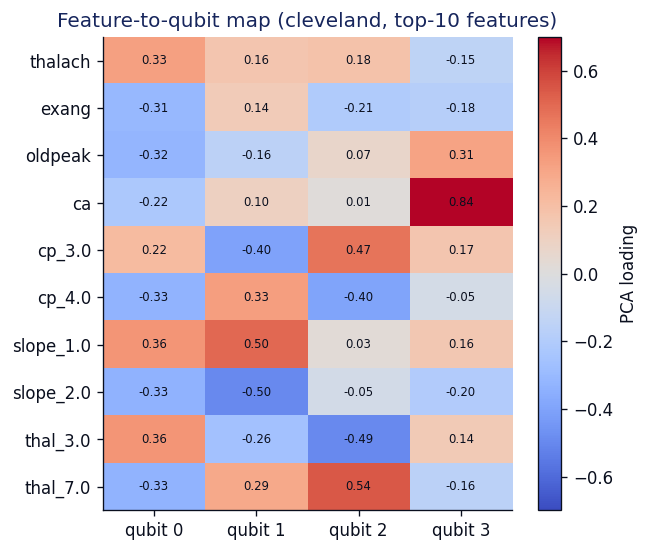

In [5]:
prep = _steps.named_steps["prep"]; sel = _steps.named_steps["select"]
feat_names = prep.get_feature_names_out()
kept = feat_names[sel.get_support()]
loadings = pd.DataFrame(pca_.components_.T, index=[n.split("__")[-1] for n in kept],
                        columns=[f"qubit {i}" for i in range(N_QUBITS)])
fig, ax = plt.subplots(figsize=(5.5, 0.35 * len(kept) + 1.2))
im = ax.imshow(loadings.values, cmap="coolwarm", vmin=-0.7, vmax=0.7, aspect="auto")
ax.set_yticks(range(len(kept))); ax.set_yticklabels(loadings.index)
ax.set_xticks(range(N_QUBITS)); ax.set_xticklabels(loadings.columns)
for i, j in itertools.product(range(len(kept)), range(N_QUBITS)):
    ax.text(j, i, f"{loadings.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
plt.colorbar(im, ax=ax, label="PCA loading")
ax.set_title(f"Feature-to-qubit map ({PRIMARY}, top-{K_BEST} features)", color=NAVY)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_feature_map.png", bbox_inches="tight"); plt.show()
loadings.round(3).to_csv(f"{RESULTS}/pca_loadings.csv")

## ধাপ ৪ — Quantum Kernels

Quantum kernel: $K(x, x') = |\langle \phi(x) | \phi(x') \rangle|^2$, যেখানে $|\phi(x)\rangle$ হলো feature map circuit-এর output state।

### দুটি feature map

**1. Angle encoding (RY):** প্রতি qubit-এ $R_Y(x_i)$। এটা product state, অর্থাৎ qubit-গুলোর মধ্যে কোনো entanglement নেই। গাণিতিকভাবে এই kernel হুবহু $\prod_i \cos^2\!\big((x_i - x'_i)/2\big)$, যেটা একটি সাধারণ classical kernel।

**এটা সৎভাবে paper-এ লিখতে হবে।** Angle-encoded QSVM-এর ভালো result মানে "quantum advantage" নয়, কারণ এটা classical কম্পিউটারে হুবহু হিসাব করা যায়। এটা রাখা হয়েছে একটি control হিসেবে। নিচের cell-এ এই সমতা সংখ্যা দিয়ে যাচাইও করা হয়েছে।

**2. ZZ feature map (Havlíček et al., 2019):** প্রতি layer-এ Hadamard, তারপর $R_Z(2x_i)$, তারপর প্রতিবেশী qubit জোড়ায় $\text{CNOT}–R_Z\big(2(\pi - x_i)(\pi - x_j)\big)–\text{CNOT}$। এখানে entanglement আছে, তাই এটাই আমাদের **মূল quantum kernel**। 4 qubit-এ এটাও classically simulate করা যায়। তাই আমাদের দাবি "advantage" নয়, বরং এই kernel family-র আচরণ বোঝা।

### দ্রুত হিসাবের কৌশল
প্রতিটি জোড়ার জন্য আলাদা circuit ($n^2$ বার) না চালিয়ে, প্রতিটি sample-এর state vector একবার হিসাব করি ($n$ বার)। তারপর $K = |S_a S_b^\dagger|^2$। গাণিতিকভাবে এটা হুবহু একই, কিন্তু বহুগুণ দ্রুত।

**Shot noise:** আসল hardware-এ kernel মাপা হয় compute–uncompute circuit-এ all-zero outcome-এর probability হিসেবে। $S$ shot-এ এর estimate হলো $\text{Binomial}(S, K)/S$। আমরা এটা হুবহু simulate করি। এরপর training kernel-কে positive semi-definite (PSD)-এ project করি, কারণ noisy kernel matrix PSD নাও থাকতে পারে।

In [6]:
import pennylane as qml

def _zz_layer(x, n):
    for i in range(n):
        qml.Hadamard(wires=i)
        qml.RZ(2.0 * x[..., i], wires=i)
    for i in range(n - 1):
        qml.CNOT(wires=[i, i + 1])
        qml.RZ(2.0 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=i + 1)
        qml.CNOT(wires=[i, i + 1])

def feature_map(x, kind, n, reps=2):
    if kind == "angle":
        for i in range(n):
            qml.RY(x[..., i], wires=i)
    elif kind == "zz":
        for _ in range(reps):
            _zz_layer(x, n)
    else:
        raise ValueError(kind)

_STATE_QNODES = {}
def get_state_qnode(kind, n, reps):
    key = (kind, n, reps)
    if key not in _STATE_QNODES:
        dev = qml.device("default.qubit", wires=n)
        @qml.qnode(dev)
        def circuit(x):
            feature_map(x, kind, n, reps)
            return qml.state()
        _STATE_QNODES[key] = circuit
    return _STATE_QNODES[key]

def states(X, kind="zz", reps=2):
    X = np.asarray(X, dtype=float)
    return np.asarray(get_state_qnode(kind, X.shape[1], reps)(X))   # broadcast over rows

def fidelity_kernel(Sa, Sb):
    return np.abs(Sa @ Sb.conj().T) ** 2

def shot_noise(K, shots, rng, symmetric=False):
    Kn = rng.binomial(shots, np.clip(K, 0, 1)) / shots
    if symmetric:
        Kn = np.triu(Kn, 1); Kn = Kn + Kn.T; np.fill_diagonal(Kn, 1.0)
        w, V = np.linalg.eigh(Kn)
        Kn = (V * np.clip(w, 0, None)) @ V.T              # project to PSD
    return Kn

# Sanity check 1: the angle kernel equals the classical cos^2 product kernel
_x = np.random.default_rng(0).uniform(0, np.pi, (6, N_QUBITS))
_Kq = fidelity_kernel(states(_x, "angle"), states(_x, "angle"))
_Kc = np.prod(np.cos((_x[:, None, :] - _x[None, :, :]) / 2) ** 2, axis=-1)
print("Angle kernel == classical cos^2 kernel:", np.allclose(_Kq, _Kc, atol=1e-10))
# Sanity check 2: ZZ kernel diagonal is 1 and matrix is PSD
_Kz = fidelity_kernel(states(_x, "zz"), states(_x, "zz"))
print("ZZ kernel diag=1:", np.allclose(np.diag(_Kz), 1), "| PSD:", np.linalg.eigvalsh(_Kz).min() > -1e-9)

Angle kernel == classical cos^2 kernel: True
ZZ kernel diag=1: True | PSD: True


### Noisy kernel (depolarizing noise)
Hardware noise model করতে প্রতি layer-এর পরে প্রতি qubit-এ depolarizing channel (probability $p$) বসানো হয়েছে। এখন state আর pure নয়, density matrix $\rho(x)$। Kernel হয় $K(x,x') = \mathrm{Tr}[\rho(x)\rho(x')]$।

Noise থাকলে diagonal আর 1 থাকে না, বরং state-এর purity-র সমান হয়। এটাই noisy quantum kernel-এর আসল আচরণ, আর এর ফলে kernel-এর contrast কমে যায়।

In [7]:
_MIXED_QNODES = {}
def get_mixed_qnode(kind, n, reps, p):
    key = (kind, n, reps, p)
    if key not in _MIXED_QNODES:
        dev = qml.device("default.mixed", wires=n)
        @qml.qnode(dev)
        def circuit(x):
            if kind == "angle":
                for i in range(n):
                    qml.RY(x[i], wires=i)
                    qml.DepolarizingChannel(p, wires=i)
            else:
                for _ in range(reps):
                    _zz_layer(x, n)
                    for i in range(n):
                        qml.DepolarizingChannel(p, wires=i)
            return qml.density_matrix(wires=range(n))
        _MIXED_QNODES[key] = circuit
    return _MIXED_QNODES[key]

def density_matrices(X, kind="zz", reps=2, p=0.0):
    X = np.asarray(X, dtype=float)
    qn = get_mixed_qnode(kind, X.shape[1], reps, float(p))
    return np.stack([np.asarray(qn(x)) for x in X])

def hs_kernel(Ra, Rb):
    d = Ra.shape[-1]
    return np.real(Ra.reshape(len(Ra), -1).conj() @ Rb.reshape(len(Rb), -1).T)

# Sanity check: with p = 0 the mixed-state kernel equals the pure-state kernel
_Km = hs_kernel(density_matrices(_x[:3], "zz", p=0.0), density_matrices(_x[:3], "zz", p=0.0))
print("Mixed kernel (p=0) == pure kernel:", np.allclose(_Km, _Kz[:3, :3], atol=1e-8))

Mixed kernel (p=0) == pure kernel: True


## ধাপ ৫ — Models

সব model sklearn-compatible estimator হিসেবে লেখা, যাতে `GridSearchCV`, `cross_validate`, `permutation_importance` সরাসরি কাজ করে।

**আগের fix করা bug-গুলো এখানেও বজায় রাখা হয়েছে:**
- Class inheritance-এ `ClassifierMixin` আগে, `BaseEstimator` পরে। উল্টো হলে `cross_val_score` NaN দেয়।
- QSVM-এ `probability=True` নেই। Probability আসে `decision_function`-এর ওপর sigmoid থেকে। Platt scaling ছোট sample-এ ভেঙে পড়ে।
- QNode বাইরে global cache-এ রাখা, estimator-এর ভেতরে নয়। তাই `joblib` pickling-এ সমস্যা হয় না।

### QSVM (Quantum Kernel SVM)
Training-এর সময় training state-গুলো রেখে দেয়। Prediction-এর সময় test state × training state kernel বানায়। `C` inner CV-তে tune হয়, ঠিক classical SVM-এর মতো। এতে দুই পক্ষ সমান সুযোগ পায়।

In [8]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.svm import SVC

class QuantumKernelSVM(ClassifierMixin, BaseEstimator):
    def __init__(self, kind="zz", reps=2, C=1.0, shots=None, noise=0.0, seed=0):
        self.kind = kind; self.reps = reps; self.C = C
        self.shots = shots; self.noise = noise; self.seed = seed

    def _embed(self, X):
        if self.noise > 0:
            return density_matrices(X, self.kind, self.reps, self.noise)
        return states(X, self.kind, self.reps)

    def _kernel(self, A, B, symmetric):
        K = hs_kernel(A, B) if self.noise > 0 else fidelity_kernel(A, B)
        if self.shots:
            K = shot_noise(K, self.shots, self._rng, symmetric=symmetric)
        return K

    def fit(self, X, y):
        self._rng = np.random.default_rng(self.seed)
        self.classes_ = np.unique(y)
        self.train_embed_ = self._embed(X)
        K = self._kernel(self.train_embed_, self.train_embed_, symmetric=True)
        self.svc_ = SVC(kernel="precomputed", C=self.C).fit(K, y)
        return self

    def decision_function(self, X):
        K = self._kernel(self._embed(X), self.train_embed_, symmetric=False)
        return self.svc_.decision_function(K)

    def predict_proba(self, X):
        d = self.decision_function(X)
        p1 = 1.0 / (1.0 + np.exp(-d))
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

### VQC (Variational Quantum Classifier)
Angle embedding → `StronglyEntanglingLayers` (2 layer × 4 qubit × 3 = **24 trainable parameter**) → qubit 0-এ $\langle Z \rangle$ → একটি trainable bias যোগ করে sigmoid।

Full-batch Adam optimiser, binary cross-entropy loss। PennyLane-এর autograd backprop ব্যবহার করা হয়েছে, আর batch broadcasting-এ পুরো training set একবারে circuit-এ যায়।

### QNN (Hybrid Quantum Neural Network)
Classical linear layer (4→4) → $\pi \cdot \tanh(\cdot)$ দিয়ে angle-কে $[-\pi, \pi]$-এ সীমিত রাখা → একই quantum core → 4টি qubit-এর $\langle Z \rangle$ → classical linear readout। পুরোটা end-to-end train হয়, সঙ্গে L2 regularisation।

**Early stopping নেই, ইচ্ছাকৃতভাবে।** Early stopping-এর জন্য validation set লাগে। সেটা test fold থেকে নিলে leakage হয়, আর inner split করলে ছোট data-য় training আরও কমে। তাই epoch সংখ্যা আগে থেকে ঠিক করা।

In [9]:
from pennylane import numpy as pnp

_VAR_QNODES = {}
def get_var_qnode(n, n_layers, readout):
    key = (n, n_layers, readout)
    if key not in _VAR_QNODES:
        dev = qml.device("default.qubit", wires=n)
        @qml.qnode(dev, diff_method="backprop")
        def circuit(x, w):
            qml.AngleEmbedding(x, wires=range(n), rotation="Y")
            qml.StronglyEntanglingLayers(w, wires=range(n))
            if readout == "single":
                return qml.expval(qml.PauliZ(0))
            return [qml.expval(qml.PauliZ(i)) for i in range(n)]
        _VAR_QNODES[key] = circuit
    return _VAR_QNODES[key]

def _bce(p, y):
    p = pnp.clip(p, 1e-7, 1 - 1e-7)
    return -pnp.mean(y * pnp.log(p) + (1 - y) * pnp.log(1 - p))

class VariationalQuantumClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, n_layers=2, epochs=VAR_EPOCHS, lr=0.1, seed=0):
        self.n_layers = n_layers; self.epochs = epochs; self.lr = lr; self.seed = seed

    def _logit(self, X, w, b):
        z = get_var_qnode(X.shape[1], self.n_layers, "single")(X, w)
        return 3.0 * z + b

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.classes_ = np.unique(y).astype(int)
        rng = np.random.default_rng(self.seed)
        w = pnp.array(rng.normal(0, 0.1, (self.n_layers, X.shape[1], 3)), requires_grad=True)
        b = pnp.array(0.0, requires_grad=True)
        opt = qml.AdamOptimizer(self.lr)
        cost = lambda w, b: _bce(1 / (1 + pnp.exp(-self._logit(X, w, b))), y)
        self.loss_curve_ = []
        for _ in range(self.epochs):
            (w, b), loss = opt.step_and_cost(cost, w, b)
            self.loss_curve_.append(float(loss))
        self.w_ = np.asarray(w); self.b_ = float(b)
        self.n_params_ = self.w_.size
        return self

    def decision_function(self, X):
        return np.asarray(self._logit(np.asarray(X, float), self.w_, self.b_))

    def predict_proba(self, X):
        p1 = 1 / (1 + np.exp(-self.decision_function(X)))
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

class QuantumNeuralNetwork(VariationalQuantumClassifier):
    def __init__(self, n_layers=2, epochs=VAR_EPOCHS, lr=0.05, l2=1e-3, seed=0):
        super().__init__(n_layers=n_layers, epochs=epochs, lr=lr, seed=seed); self.l2 = l2

    def _forward(self, X, P):
        Win, bin_, w, Wout, bout = P
        angles = np.pi * pnp.tanh(X @ Win + bin_)
        z = pnp.stack(get_var_qnode(X.shape[1], self.n_layers, "all")(angles, w), axis=-1)
        return z @ Wout + bout

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.classes_ = np.unique(y).astype(int)
        n = X.shape[1]; rng = np.random.default_rng(self.seed)
        P = [pnp.array(rng.normal(0, 0.5, (n, n)), requires_grad=True),
             pnp.zeros(n, requires_grad=True),
             pnp.array(rng.normal(0, 0.1, (self.n_layers, n, 3)), requires_grad=True),
             pnp.array(rng.normal(0, 0.5, n), requires_grad=True),
             pnp.array(0.0, requires_grad=True)]
        opt = qml.AdamOptimizer(self.lr)
        def cost(*P):
            p = 1 / (1 + pnp.exp(-self._forward(X, P)))
            return _bce(p, y) + self.l2 * (pnp.sum(P[0] ** 2) + pnp.sum(P[3] ** 2))
        self.loss_curve_ = []
        for _ in range(self.epochs):
            P, loss = opt.step_and_cost(cost, *P)
            P = list(P); self.loss_curve_.append(float(loss))
        self.P_ = [np.asarray(p) for p in P]
        self.n_params_ = int(sum(p.size for p in self.P_))
        return self

    def decision_function(self, X):
        return np.asarray(self._forward(np.asarray(X, float), self.P_))

# Smoke test on random data
_Xs = np.random.default_rng(1).uniform(0, 1, (40, 4)); _ys = (_Xs.sum(1) > 2).astype(int)
for m in [QuantumKernelSVM(), VariationalQuantumClassifier(epochs=3), QuantumNeuralNetwork(epochs=3)]:
    m.fit(_Xs, _ys); print(type(m).__name__, "OK, proba shape", m.predict_proba(_Xs).shape)

QuantumKernelSVM OK, proba shape (40, 2)
VariationalQuantumClassifier OK, proba shape (40, 2)
QuantumNeuralNetwork OK, proba shape (40, 2)


## ধাপ ৬ — Model Registry

প্রতিটি kernel model-এর **দুটি hyperparameter inner 3-fold CV-তে** (nested CV) বাছাই হয়:
- `C ∈ {0.1, 1, 10}`, সব SVM ও LogReg-এর জন্য।
- **Bandwidth**, একই আপেক্ষিক grid-এ:
  - QSVM: α ∈ {π/8, π/4, π/2}। Angle ½×, 1×, 2× হয়, তাই দূরত্বের বর্গ ¼×, 1×, 4×।
  - RBF-SVM: gamma ∈ {¼×, 1×, 4×} × sklearn-এর `'scale'` মান।

এভাবে quantum আর classical দুই পক্ষই হুবহু সমান tuning সুযোগ পায়। Test fold কখনো কোনো বাছাইয়ে ব্যবহার হয় না। RBF-এর gamma training fold-এর variance থেকে হিসাব হয়, তাই সেখানেও কোনো leakage নেই।

Logistic Regression-এ bandwidth নেই, তাই শুধু `C` tune হয়।

Random Forest-এর hyperparameter আগে থেকে ঠিক করা (300 tree, `max_depth=5`)। ছোট data-য় গভীর tree overfit করে, তাই এই সীমা।

**VQC-র angle range [0, π]:** VQC-তে কোনো kernel নেই, angle সরাসরি trainable circuit-এ যায়। [0, π/4]-এর মতো সরু range-এ সব রোগীর state প্রায় একই হয়ে যায়, আর circuit তাদের আলাদা করতে পারে না। তাই VQC-র জন্য α = π। এটা আগে থেকে ঠিক করা, result দেখে বদলানো নয়। QNN-এ সমস্যা নেই, কারণ তার classical input layer নিজেই scale শিখে নেয়।

In [10]:
# Every kernel model now tunes BOTH C and its bandwidth in the inner CV, on the same
# 3-point relative grid (x1/4, x1, x4 in squared distance):
#   QSVM:    alpha in {pi/8, pi/4, pi/2}  (angle x1/2, x1, x2  ->  distance^2 x1/4, x1, x4)
#   RBF-SVM: gamma = {0.25, 1, 4} x sklearn 'scale' value
# The outer test fold is never used for any choice.
from sklearn.model_selection import (StratifiedKFold, GridSearchCV, cross_validate,
                                     permutation_test_score)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score,
                             f1_score, recall_score, brier_score_loss, make_scorer)

class ScaledRBFSVM(ClassifierMixin, BaseEstimator):
    """RBF-SVM whose gamma is a multiple of sklearn's 'scale' value, computed on the training fold."""
    def __init__(self, C=1.0, gamma_mult=1.0):
        self.C = C; self.gamma_mult = gamma_mult
    def fit(self, X, y):
        X = np.asarray(X, float); self.classes_ = np.unique(y)
        var = X.var()
        self.gamma_ = self.gamma_mult / (X.shape[1] * var) if var > 0 else 1.0
        self.svc_ = SVC(kernel="rbf", C=self.C, gamma=self.gamma_).fit(X, y)
        return self
    def decision_function(self, X):
        return self.svc_.decision_function(np.asarray(X, float))
    def predict(self, X):
        return self.svc_.predict(np.asarray(X, float))

C_VALUES = [0.1, 1.0, 10.0]
ALPHA_GRID = [(0.0, np.pi / 8), (0.0, np.pi / 4), (0.0, np.pi / 2)]
GAMMA_MULTS = [0.25, 1.0, 4.0]
C_GRID = {"model__C": C_VALUES}

def build_model(name, X, nominal, seed, alpha=ANGLE_SCALE):
    inner = StratifiedKFold(3, shuffle=True, random_state=seed)
    def tuned(est, grid, **kw):
        return GridSearchCV(make_pipeline(est, X, nominal, seed, alpha=alpha, **kw),
                            grid, scoring="roc_auc", cv=inner)
    q_grid = {"model__C": C_VALUES, "angles__feature_range": ALPHA_GRID}
    r_grid = {"model__C": C_VALUES, "model__gamma_mult": GAMMA_MULTS}
    if name == "QSVM-ZZ":     return tuned(QuantumKernelSVM("zz", seed=seed), q_grid)
    if name == "QSVM-Angle":  return tuned(QuantumKernelSVM("angle", seed=seed), q_grid)
    if name == "RBF-SVM":     return tuned(ScaledRBFSVM(), r_grid)
    if name == "LogReg":      return tuned(LogisticRegression(max_iter=2000), C_GRID)
    if name == "RandomForest":
        return make_pipeline(RandomForestClassifier(300, max_depth=5, random_state=seed),
                             X, nominal, seed, alpha=alpha)
    if name == "VQC":
        return make_pipeline(VariationalQuantumClassifier(seed=seed), X, nominal, seed, alpha=np.pi)
    if name == "QNN":
        return make_pipeline(QuantumNeuralNetwork(seed=seed), X, nominal, seed, alpha=alpha)
    if name == "RBF-SVM (full features)":
        return tuned(ScaledRBFSVM(), r_grid, reduce=False)
    if name == "LogReg (full features)":
        return tuned(LogisticRegression(max_iter=2000), C_GRID, reduce=False)
    raise ValueError(name)

CORE_MODELS = ["QSVM-ZZ", "QSVM-Angle", "RBF-SVM", "LogReg", "RandomForest",
               "RBF-SVM (full features)", "LogReg (full features)"]
VAR_MODELS = ["VQC", "QNN"]

# Results from the old (untuned-bandwidth) registry must not be reused by the resume logic
_marker = "results/.registry_v2"
if not os.path.exists(_marker):
    for f in ["results/benchmark_folds.csv"]:
        if os.path.exists(f):
            os.remove(f); print("Removed old cached results:", f)
    open(_marker, "w").write("bandwidth-tuned registry")
print("Registry v2 ready: C + bandwidth tuned in inner CV for all kernel models.")

Registry v2 ready: C + bandwidth tuned in inner CV for all kernel models.


## ধাপ ৭ — Benchmark Engine

**Protocol:** প্রতি seed-এ stratified 5-fold CV। সব model **হুবহু একই fold** পায় (একই `random_state`)। তাই paired statistical test বৈধ।

প্রতি fold-এ যা রেকর্ড হয়:
- **ROC-AUC** (মূল metric — threshold-নিরপেক্ষ, class imbalance-এ স্থিতিশীল)
- Accuracy, Balanced accuracy, F1, Sensitivity (রোগী ধরা), Specificity (সুস্থকে সুস্থ বলা)
- **Brier score** (probability কতটা নির্ভরযোগ্য)
- **Train AUC** আর **gap = train AUC − validation AUC** → এটাই overfitting-এর আসল মাপকাঠি

Medical screening-এ sensitivity বিশেষ গুরুত্বপূর্ণ, কারণ রোগী মিস করা (false negative) সুস্থকে ভুল flag করার চেয়ে বেশি ক্ষতিকর।

In [11]:
def _proba(est, X):
    """Positive-class probability. Models without predict_proba (RBF-SVM) use the same
    sigmoid-on-decision-function mapping as QSVM, so Brier scores are comparable."""
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)[:, 1]
    return 1.0 / (1.0 + np.exp(-est.decision_function(X)))

def _brier(est, X, y):
    return brier_score_loss(y, _proba(est, X))

SCORING = {
    "auc": "roc_auc",
    "acc": "accuracy",
    "bacc": "balanced_accuracy",
    "f1": "f1",
    "sens": make_scorer(recall_score, pos_label=1),
    "spec": make_scorer(recall_score, pos_label=0),
    "brier": _brier,
}

def evaluate(name, dataset, seeds=SEEDS, alpha=ANGLE_SCALE, verbose=True):
    X, y, nominal = DATA[dataset]
    rows = []
    for seed in seeds:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
        t0 = time.time()
        res = cross_validate(build_model(name, X, nominal, seed, alpha), X, y, cv=cv,
                             scoring=SCORING, return_train_score=True, n_jobs=1,
                             error_score="raise")
        for f in range(N_FOLDS):
            rows.append(dict(dataset=dataset, model=name, seed=seed, fold=f,
                             train_auc=res["train_auc"][f],
                             **{k: res[f"test_{k}"][f]
                                for k in SCORING}))
        if verbose:
            a = res["test_auc"]; print(f"  {dataset:10s} {name:26s} seed {seed}: "
                                       f"AUC {a.mean():.3f}  ({time.time()-t0:.0f}s)")
    df = pd.DataFrame(rows); df["gap"] = df["train_auc"] - df["auc"]
    return df

## ধাপ ৮ — মূল Benchmark চালানো

সব dataset-এ core model চলে। VQC/QNN শুধু primary dataset-এ চলে, কারণ এগুলো ধীর।

প্রতিটি result সঙ্গে সঙ্গে CSV-তে save হয়। Colab disconnect হলে আবার চালালে আগে শেষ হওয়া অংশ skip হবে।

In [12]:
FOLD_CSV = f"{RESULTS}/benchmark_folds.csv"
done = pd.read_csv(FOLD_CSV) if os.path.exists(FOLD_CSV) else pd.DataFrame()

jobs = [(d, m) for d in DATA for m in CORE_MODELS]
if RUN_VARIATIONAL:
    jobs += [(PRIMARY, m) for m in VAR_MODELS]

for d, m in jobs:
    if len(done) and ((done.dataset == d) & (done.model == m)
                      & done.seed.isin(SEEDS)).sum() == len(SEEDS) * N_FOLDS:
        continue
    df = evaluate(m, d)
    done = pd.concat([done[~((done.dataset == d) & (done.model == m))] if len(done) else done, df])
    done.to_csv(FOLD_CSV, index=False)

folds = done[done.seed.isin(SEEDS)].copy()

def summarise(folds):
    # Average over folds within a seed first, then mean +/- std across seeds
    per_seed = folds.groupby(["dataset", "model", "seed"]).mean(numeric_only=True).reset_index()
    agg = per_seed.groupby(["dataset", "model"]).agg(
        **{f"{k}_mean": (k, "mean") for k in ["auc", "acc", "bacc", "f1", "sens", "spec",
                                              "brier", "train_auc", "gap"]},
        auc_std=("auc", "std"), acc_std=("acc", "std")).reset_index()
    return agg.sort_values(["dataset", "auc_mean"], ascending=[True, False])

summary = summarise(folds)
summary.to_csv(f"{RESULTS}/benchmark_summary.csv", index=False)
pd.set_option("display.width", 200)
display(summary.round(3))

  cleveland  QSVM-ZZ                    seed 0: AUC 0.885  (25s)
  cleveland  QSVM-ZZ                    seed 1: AUC 0.884  (15s)
  cleveland  QSVM-ZZ                    seed 2: AUC 0.873  (15s)
  cleveland  QSVM-ZZ                    seed 3: AUC 0.880  (16s)
  cleveland  QSVM-ZZ                    seed 4: AUC 0.891  (16s)
  cleveland  QSVM-Angle                 seed 0: AUC 0.913  (11s)
  cleveland  QSVM-Angle                 seed 1: AUC 0.911  (12s)
  cleveland  QSVM-Angle                 seed 2: AUC 0.896  (13s)
  cleveland  QSVM-Angle                 seed 3: AUC 0.911  (12s)
  cleveland  QSVM-Angle                 seed 4: AUC 0.913  (12s)
  cleveland  RBF-SVM                    seed 0: AUC 0.909  (6s)
  cleveland  RBF-SVM                    seed 1: AUC 0.910  (7s)
  cleveland  RBF-SVM                    seed 2: AUC 0.894  (7s)
  cleveland  RBF-SVM                    seed 3: AUC 0.912  (7s)
  cleveland  RBF-SVM                    seed 4: AUC 0.912  (7s)
  cleveland  LogReg           

,dataset,model,auc_mean,acc_mean,bacc_mean,f1_mean,sens_mean,spec_mean,brier_mean,train_auc_mean,gap_mean,auc_std,acc_std
0,cleveland,LogReg,0.911,0.838,0.835,0.819,0.801,0.869,0.133,0.919,0.008,0.007,0.007
3,cleveland,QSVM-Angle,0.909,0.843,0.838,0.819,0.781,0.895,0.149,0.920,0.011,0.007,0.010
6,cleveland,RBF-SVM (full features),0.908,0.834,0.833,0.820,0.829,0.838,0.159,0.921,0.013,0.005,0.012
5,cleveland,RBF-SVM,0.907,0.838,0.835,0.818,0.800,0.870,0.138,0.921,0.014,0.008,0.010
1,cleveland,LogReg (full features),0.907,0.838,0.835,0.820,0.808,0.862,0.121,0.936,0.029,0.004,0.008
2,cleveland,QNN,0.901,0.838,0.835,0.818,0.796,0.874,0.121,0.928,0.027,0.007,0.009
7,cleveland,RandomForest,0.897,0.827,0.824,0.806,0.785,0.862,0.131,0.988,0.091,0.003,0.014
8,cleveland,VQC,0.889,0.813,0.813,0.801,0.824,0.802,0.140,0.903,0.014,0.006,0.016
4,cleveland,QSVM-ZZ,0.883,0.809,0.807,0.787,0.774,0.839,0.146,0.925,0.042,0.007,0.010
10,golub,LogReg (full features),0.998,0.983,0.978,0.988,0.996,0.960,0.023,1.000,0.002,0.002,0.006


## ধাপ ৯ — Statistical Testing

Mean ± std দেখে "সমান" বা "ভালো" বলা যায় না। তিনটি test ব্যবহার করা হয়েছে:

**1. Nadeau–Bengio corrected resampled t-test.** Repeated CV-তে training set-গুলো একে অপরের সাথে overlap করে, তাই সাধারণ t-test variance কম ধরে এবং মিথ্যা "significant" দেয়। এই সংশোধিত test সেই overlap হিসাবে নেয়: $\hat\sigma^2 \cdot (1/J + n_{test}/n_{train})$।

**2. TOST (Two One-Sided Tests) equivalence test.** "পার্থক্য significant নয়" মানে "সমান" নয়। শুধু এটুকু বলে যে পার্থক্য প্রমাণ করা যায়নি। Equivalence দাবি করতে হলে আলাদাভাবে প্রমাণ করতে হয় যে পার্থক্য একটি margin ($\pm 0.02$ AUC)-এর ভেতরে। **আমাদের মূল দাবির জন্য এটাই সঠিক test।**

**3. Holm–Bonferroni correction.** অনেকগুলো তুলনা একসাথে করলে কোনো একটায় কাকতালীয়ভাবে "significant" আসার সম্ভাবনা বাড়ে। Holm সেটা নিয়ন্ত্রণ করে।

সব তুলনা paired, কারণ সব model একই fold-এ চলেছে।

In [13]:
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b); J = len(d)
    var = d.var(ddof=1) * (1 / J + n_test / n_train)
    se = np.sqrt(var) if var > 0 else 1e-12
    t = d.mean() / se
    return d.mean(), se, t, 2 * stats.t.sf(abs(t), J - 1), J - 1

def tost(mean_d, se, df, margin=EQUIV_MARGIN):
    p_low = stats.t.sf((mean_d + margin) / se, df)      # H0: d <= -margin
    p_high = stats.t.cdf((mean_d - margin) / se, df)    # H0: d >= +margin
    return max(p_low, p_high)

def holm(pvals):
    p = np.asarray(pvals); order = np.argsort(p); adj = np.empty_like(p); m = len(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx]); adj[idx] = min(running, 1.0)
    return adj

REFERENCE = "QSVM-ZZ"
stat_rows = []
for d in folds.dataset.unique():
    n = len(DATA[d][1]); n_test = n / N_FOLDS; n_train = n - n_test
    f = folds[folds.dataset == d].sort_values(["seed", "fold"])
    ref = f[f.model == REFERENCE]
    for other in f.model.unique():
        if other == REFERENCE: continue
        o = f[f.model == other]
        m = ref.merge(o, on=["seed", "fold"], suffixes=("_q", "_c"))
        md, se, t, p, df_ = corrected_ttest(m.auc_q, m.auc_c, n_train, n_test)
        w_p = stats.wilcoxon(m.auc_q, m.auc_c).pvalue if np.any(m.auc_q != m.auc_c) else 1.0
        stat_rows.append(dict(dataset=d, comparison=f"{REFERENCE} vs {other}", delta_auc=md,
                              ci95_low=md - stats.t.ppf(.975, df_) * se,
                              ci95_high=md + stats.t.ppf(.975, df_) * se,
                              p_ttest=p, p_wilcoxon=w_p, p_tost=tost(md, se, df_)))
st = pd.DataFrame(stat_rows)
st["p_ttest_holm"] = st.groupby("dataset")["p_ttest"].transform(holm)
st["p_tost_holm"] = st.groupby("dataset")["p_tost"].transform(holm)

def verdict(r):
    if r.p_ttest_holm < 0.05:
        return "QSVM better" if r.delta_auc > 0 else "QSVM worse"
    if r.p_tost_holm < 0.05:
        return f"equivalent (±{EQUIV_MARGIN})"
    return "inconclusive"
st["verdict"] = st.apply(verdict, axis=1)
st.to_csv(f"{RESULTS}/statistical_tests.csv", index=False)
display(st.round(4))

,dataset,comparison,delta_auc,ci95_low,ci95_high,p_ttest,p_wilcoxon,p_tost,p_ttest_holm,p_tost_holm,verdict
0,cleveland,QSVM-ZZ vs QSVM-Angle,-0.0262,-0.0543,0.0020,0.0674,0.0001,0.6720,0.4716,1.0000,inconclusive
1,cleveland,QSVM-ZZ vs RBF-SVM,-0.0245,-0.0518,0.0028,0.0760,0.0002,0.6318,0.4716,1.0000,inconclusive
2,cleveland,QSVM-ZZ vs LogReg,-0.0282,-0.0541,-0.0023,0.0342,0.0000,0.7400,0.2734,1.0000,inconclusive
3,cleveland,QSVM-ZZ vs RandomForest,-0.0139,-0.0426,0.0147,0.3248,0.0173,0.3332,0.6514,1.0000,inconclusive
4,cleveland,QSVM-ZZ vs RBF-SVM (full features),-0.0251,-0.0540,0.0038,0.0856,0.0001,0.6408,0.4716,1.0000,inconclusive
5,cleveland,QSVM-ZZ vs LogReg (full features),-0.0240,-0.0524,0.0044,0.0934,0.0003,0.6142,0.4716,1.0000,inconclusive
6,cleveland,QSVM-ZZ vs VQC,-0.0063,-0.0328,0.0202,0.6276,0.3002,0.1484,0.6514,1.0000,inconclusive
7,cleveland,QSVM-ZZ vs QNN,-0.0181,-0.0476,0.0114,0.2171,0.0043,0.4478,0.6514,1.0000,inconclusive
8,pima,QSVM-ZZ vs QSVM-Angle,-0.0113,-0.0259,0.0032,0.1212,0.0011,0.1149,0.3636,0.4598,inconclusive
9,pima,QSVM-ZZ vs RBF-SVM,-0.0135,-0.0276,0.0005,0.0585,0.0000,0.1758,0.3513,0.5273,inconclusive


### Verdict পড়ার নিয়ম
- **equivalent:** পার্থক্য ±0.02 AUC-এর ভেতরে, আর এটা statistically প্রমাণিত। এটাই আমাদের সবচেয়ে শক্ত দাবি হতে পারে।
- **inconclusive:** পার্থক্যও প্রমাণিত নয়, সমতাও নয়। সাধারণত variance বেশি বা data কম হলে এটা আসে। এটা negative result হিসেবে সৎভাবে রিপোর্ট করতে হবে।
- **QSVM better/worse:** Holm correction-এর পরেও significant পার্থক্য।

## ধাপ ১০ — Validity Gate (overfitting ও leakage পরীক্ষা)

এই cell প্রতিটি result স্বয়ংক্রিয়ভাবে পরীক্ষা করে। কোনো flag উঠলে সেই result paper-এ দেওয়ার আগে অবশ্যই কারণ খুঁজতে হবে।

In [14]:
gate = summary[["dataset", "model", "auc_mean", "acc_mean", "train_auc_mean", "gap_mean"]].copy()
gate["overfit_flag"] = gate.gap_mean > GAP_FLAG
gate["leak_suspect"] = gate.apply(lambda r: r.auc_mean > PLAUSIBLE_AUC_CEILING.get(r.dataset, 1), axis=1)
gate.to_csv(f"{RESULTS}/validity_gate.csv", index=False)
display(gate.round(3))
flags = gate[gate.overfit_flag | gate.leak_suspect]
print("\nFLAGGED:" if len(flags) else "\nNo validity flags raised.")
if len(flags): display(flags)

,dataset,model,auc_mean,acc_mean,train_auc_mean,gap_mean,overfit_flag,leak_suspect
0,cleveland,LogReg,0.911,0.838,0.919,0.008,False,False
3,cleveland,QSVM-Angle,0.909,0.843,0.920,0.011,False,False
6,cleveland,RBF-SVM (full features),0.908,0.834,0.921,0.013,False,False
5,cleveland,RBF-SVM,0.907,0.838,0.921,0.014,False,False
1,cleveland,LogReg (full features),0.907,0.838,0.936,0.029,False,False
2,cleveland,QNN,0.901,0.838,0.928,0.027,False,False
7,cleveland,RandomForest,0.897,0.827,0.988,0.091,True,False
8,cleveland,VQC,0.889,0.813,0.903,0.014,False,False
4,cleveland,QSVM-ZZ,0.883,0.809,0.925,0.042,False,False
10,golub,LogReg (full features),0.998,0.983,1.000,0.002,False,False



FLAGGED:


,dataset,model,auc_mean,acc_mean,train_auc_mean,gap_mean,overfit_flag,leak_suspect
7,cleveland,RandomForest,0.896695,0.827049,0.988137,0.091442,True,False
15,golub,RandomForest,0.949911,0.924952,1.000000,0.050089,True,False
22,pima,RandomForest,0.812123,0.735148,0.918650,0.106527,True,False


### Permutation test: model কি আসলেই কিছু শিখছে?
Label এলোমেলো করে (shuffle) পুরো CV আবার চালানো হয়। Pipeline leak-free হলে shuffled label-এ AUC ~0.5 হওয়ার কথা। আসল AUC যদি shuffled AUC-এর distribution থেকে অনেক উপরে থাকে, তাহলে p-value ছোট হবে, অর্থাৎ model সত্যিকারের signal শিখছে।

**Shuffled AUC যদি 0.5-এর অনেক উপরে আসে → pipeline-এ leakage আছে।** এটা leakage ধরার সবচেয়ে নির্ভরযোগ্য পরীক্ষাগুলোর একটি।

In [15]:
perm_rows = []
for d in DATA:
    X, y, nominal = DATA[d]
    for name in ["QSVM-ZZ", "LogReg"]:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=0)
        est = make_pipeline(QuantumKernelSVM("zz") if name == "QSVM-ZZ"
                            else LogisticRegression(max_iter=2000), X, nominal)
        score, perm_scores, p = permutation_test_score(est, X, y, cv=cv, scoring="roc_auc",
                                                       n_permutations=N_PERMUTATIONS,
                                                       random_state=0, n_jobs=1)
        perm_rows.append(dict(dataset=d, model=name, auc=score, perm_auc_mean=perm_scores.mean(),
                              perm_auc_std=perm_scores.std(), p_value=p))
        print(f"{d:10s} {name:8s} AUC {score:.3f} | shuffled {perm_scores.mean():.3f}"
              f"±{perm_scores.std():.3f} | p={p:.4f}")
perm = pd.DataFrame(perm_rows); perm.to_csv(f"{RESULTS}/permutation_test.csv", index=False)

cleveland  QSVM-ZZ  AUC 0.888 | shuffled 0.501±0.039 | p=0.0050
cleveland  LogReg   AUC 0.915 | shuffled 0.501±0.045 | p=0.0050
pima       QSVM-ZZ  AUC 0.785 | shuffled 0.499±0.031 | p=0.0050
pima       LogReg   AUC 0.811 | shuffled 0.500±0.030 | p=0.0050
wisconsin  QSVM-ZZ  AUC 0.979 | shuffled 0.500±0.028 | p=0.0050
wisconsin  LogReg   AUC 0.986 | shuffled 0.502±0.032 | p=0.0050
golub      QSVM-ZZ  AUC 0.965 | shuffled 0.495±0.084 | p=0.0050
golub      LogReg   AUC 0.987 | shuffled 0.488±0.094 | p=0.0050


### Leakage demonstration: ভুল pipeline কতটা মিথ্যা ফল দেয়

এটা paper-এর একটি শক্তিশালী অংশ হতে পারে। একই model দুইভাবে চালানো হয়:
- **Leaky (ভুল):** পুরো dataset-এ scaling, feature selection, PCA fit করে, তারপর CV। অনেক published কাজ এভাবেই করে।
- **Leak-free (সঠিক):** সব ধাপ fold-এর ভেতরে।

High-dimensional data (Golub: 7,129 gene, মাত্র 72 রোগী)-এ leaky feature selection বিশাল মিথ্যা উন্নতি দেখায়। কারণ পুরো data দেখে বাছাই করা gene-গুলো test রোগীদের label-এর সাথেও মিলে যায়।

**Random-label control:** Golub-এ label এলোমেলো করে leaky pipeline চালালে, সত্যিকারের কোনো signal না থাকা সত্ত্বেও AUC অনেক বেশি আসে। এটাই leakage-এর সবচেয়ে পরিষ্কার প্রমাণ।

In [16]:
def leaky_auc(d, model_fn, y_override=None, seeds=SEEDS):
    X, y, nominal = DATA[d]; y = y if y_override is None else y_override
    steps = ImbPipeline(make_feature_steps(X, nominal)[:-1])
    Z = steps.fit_transform(X, y)                              # fitted on ALL data -> leak
    out = []
    for s in seeds:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=s)
        out.append(cross_validate(model_fn(), Z, y, cv=cv, scoring="roc_auc")["test_score"].mean())
    return np.mean(out), np.std(out)

def clean_auc(d, model_fn, y_override=None, seeds=SEEDS):
    X, y, nominal = DATA[d]; y = y if y_override is None else y_override
    out = []
    for s in seeds:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=s)
        out.append(cross_validate(make_pipeline(model_fn(), X, nominal, s), X, y, cv=cv,
                                  scoring="roc_auc")["test_score"].mean())
    return np.mean(out), np.std(out)

leak_rows = []
for d in DATA:
    y_rand = np.random.default_rng(123).permutation(DATA[d][1])
    for label, yo in [("true labels", None), ("RANDOM labels", y_rand)]:
        for mname, fn in [("QSVM-ZZ", lambda: QuantumKernelSVM("zz")),
                          ("LogReg", lambda: LogisticRegression(max_iter=2000))]:
            lm, ls = leaky_auc(d, fn, yo); cm, cs = clean_auc(d, fn, yo)
            leak_rows.append(dict(dataset=d, labels=label, model=mname, leaky_auc=lm,
                                  leak_free_auc=cm, inflation=lm - cm))
            print(f"{d:10s} {label:13s} {mname:8s} leaky {lm:.3f} | leak-free {cm:.3f} | "
                  f"inflation {lm-cm:+.3f}")
leak = pd.DataFrame(leak_rows); leak.to_csv(f"{RESULTS}/leakage_demo.csv", index=False)

cleveland  true labels   QSVM-ZZ  leaky 0.863 | leak-free 0.871 | inflation -0.008
cleveland  true labels   LogReg   leaky 0.914 | leak-free 0.911 | inflation +0.003
cleveland  RANDOM labels QSVM-ZZ  leaky 0.517 | leak-free 0.486 | inflation +0.031
cleveland  RANDOM labels LogReg   leaky 0.517 | leak-free 0.473 | inflation +0.044
pima       true labels   QSVM-ZZ  leaky 0.792 | leak-free 0.789 | inflation +0.004
pima       true labels   LogReg   leaky 0.812 | leak-free 0.812 | inflation -0.000
pima       RANDOM labels QSVM-ZZ  leaky 0.539 | leak-free 0.528 | inflation +0.011
pima       RANDOM labels LogReg   leaky 0.496 | leak-free 0.492 | inflation +0.004
wisconsin  true labels   QSVM-ZZ  leaky 0.979 | leak-free 0.978 | inflation +0.001
wisconsin  true labels   LogReg   leaky 0.985 | leak-free 0.985 | inflation +0.000
wisconsin  RANDOM labels QSVM-ZZ  leaky 0.535 | leak-free 0.491 | inflation +0.044
wisconsin  RANDOM labels LogReg   leaky 0.502 | leak-free 0.485 | inflation +0.017
golu

## ধাপ ১১ — Bandwidth Sweep (α → kernel concentration → overfitting)

প্রতিটি α-এর জন্য চারটি জিনিস মাপা হয়:
- **Validation AUC** আর **train–val gap**
- **Off-diagonal kernel mean:** 1-এর কাছাকাছি মানে সব রোগী প্রায় একই রকম দেখাচ্ছে (kernel অতি-মসৃণ, underfit)
- **Off-diagonal kernel variance:** 0-এর কাছাকাছি মানে **exponential concentration** (Thanasilp et al., 2024)। তখন kernel কোনো তথ্য বহন করে না। Concentration দুই প্রান্তেই ঘটে: খুব ছোট α-তে সব kernel মান 1-এর কাছে জমে, খুব বড় α-তে 0-এর কাছে। তাই variance মাঝের কোনো α-তে সর্বোচ্চ হওয়ার কথা।
- **Kernel-target alignment (KTA):** kernel matrix label structure-এর সাথে কতটা মেলে

**সতর্কতা:** এই sweep-এ C fixed (C=1), tune করা হয়নি। কারণ আমরা bandwidth-এর বিশুদ্ধ প্রভাব দেখতে চাই। ফলে এখানে π/4-এর AUC মূল benchmark-এর QSVM-এর সাথে হুবহু মিলবে না (সেখানে C tune হয়েছে)। **Paper-এ এই পার্থক্য স্পষ্টভাবে লিখতে হবে।** আগের version-এ এই অসংগতির কোনো ব্যাখ্যা ছিল না।

In [17]:
def kernel_diagnostics(K, y):
    off = K[~np.eye(len(K), dtype=bool)]
    yy = np.where(y == 1, 1.0, -1.0); Y = np.outer(yy, yy)
    kta = (K * Y).sum() / (np.linalg.norm(K) * np.linalg.norm(Y))
    w = np.clip(np.linalg.eigvalsh(K), 0, None); w = w / w.sum()
    eff_dim = 1.0 / np.sum(w ** 2)
    return off.mean(), off.var(), kta, eff_dim

bw_rows = []
for kind in ["zz", "angle"]:
    X, y, nominal = DATA[PRIMARY]
    for label, a in BANDWIDTHS.items():
        for seed in SEEDS:
            cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
            for f, (tr, te) in enumerate(cv.split(X, y)):
                pipe = make_pipeline(QuantumKernelSVM(kind, C=1.0, seed=seed), X, nominal, seed, alpha=a)
                pipe.fit(X.iloc[tr], y[tr])
                auc_te = roc_auc_score(y[te], _proba(pipe, X.iloc[te]))
                auc_tr = roc_auc_score(y[tr], _proba(pipe, X.iloc[tr]))
                Ztr = ImbPipeline(pipe.steps[:-2]).transform(X.iloc[tr])
                S = states(Ztr, kind)
                km, kv, kta, ed = kernel_diagnostics(fidelity_kernel(S, S), y[tr])
                bw_rows.append(dict(kind=kind, alpha=label, alpha_val=a, seed=seed, fold=f,
                                    auc=auc_te, train_auc=auc_tr, gap=auc_tr - auc_te,
                                    k_mean=km, k_var=kv, kta=kta, eff_dim=ed))
        r = pd.DataFrame(bw_rows); r = r[(r.kind == kind) & (r.alpha == label)]
        print(f"{kind:5s} alpha={label:5s} AUC {r.auc.mean():.3f}  gap {r.gap.mean():.3f}  "
              f"K_mean {r.k_mean.mean():.3f}  K_var {r.k_var.mean():.4f}  KTA {r.kta.mean():.3f}")
bw = pd.DataFrame(bw_rows); bw.to_csv(f"{RESULTS}/bandwidth_sweep.csv", index=False)
bw_sum = bw.groupby(["kind", "alpha", "alpha_val"]).agg(
    auc=("auc", "mean"), auc_std=("auc", "std"), gap=("gap", "mean"),
    k_mean=("k_mean", "mean"), k_var=("k_var", "mean"), kta=("kta", "mean"),
    eff_dim=("eff_dim", "mean")).reset_index().sort_values(["kind", "alpha_val"])
display(bw_sum.round(4))
# Monotonicity check that supports (or refutes) the bandwidth claim
for kind in ["zz", "angle"]:
    s = bw_sum[bw_sum.kind == kind]
    rho, p = stats.spearmanr(s.alpha_val, s.gap)
    print(f"{kind}: Spearman(alpha, gap) = {rho:.2f} (p={p:.3f}, n={len(s)} points)")

zz    alpha=pi/16 AUC 0.873  gap 0.011  K_mean 0.798  K_var 0.0180  KTA 0.038
zz    alpha=pi/8  AUC 0.884  gap 0.024  K_mean 0.350  K_var 0.0826  KTA 0.153
zz    alpha=pi/4  AUC 0.871  gap 0.056  K_mean 0.149  K_var 0.0429  KTA 0.164
zz    alpha=pi/2  AUC 0.838  gap 0.099  K_mean 0.118  K_var 0.0261  KTA 0.125
zz    alpha=pi    AUC 0.797  gap 0.144  K_mean 0.097  K_var 0.0176  KTA 0.090
angle alpha=pi/16 AUC 0.908  gap 0.006  K_mean 0.996  K_var 0.0000  KTA 0.008
angle alpha=pi/8  AUC 0.908  gap 0.007  K_mean 0.985  K_var 0.0001  KTA 0.010
angle alpha=pi/4  AUC 0.910  gap 0.007  K_mean 0.941  K_var 0.0012  KTA 0.019
angle alpha=pi/2  AUC 0.910  gap 0.010  K_mean 0.785  K_var 0.0138  KTA 0.057
angle alpha=pi    AUC 0.909  gap 0.015  K_mean 0.405  K_var 0.0649  KTA 0.190


,kind,alpha,alpha_val,auc,auc_std,gap,k_mean,k_var,kta,eff_dim
1,angle,pi/16,0.1963,0.9085,0.0471,0.0063,0.9962,0.0000,0.0076,1.0077
4,angle,pi/8,0.3927,0.9076,0.0475,0.0070,0.9847,0.0001,0.0098,1.0310
3,angle,pi/4,0.7854,0.9099,0.0455,0.0072,0.9405,0.0012,0.0190,1.1284
2,angle,pi/2,1.5708,0.9101,0.0453,0.0100,0.7847,0.0138,0.0568,1.5849
0,angle,pi,3.1416,0.9089,0.0431,0.0154,0.4047,0.0649,0.1904,4.3186
6,zz,pi/16,0.1963,0.8734,0.0618,0.0114,0.7984,0.0180,0.0378,1.5229
9,zz,pi/8,0.3927,0.8841,0.0572,0.0241,0.3500,0.0826,0.1532,4.8044
8,zz,pi/4,0.7854,0.8709,0.0521,0.0557,0.1493,0.0429,0.1640,14.5929
7,zz,pi/2,1.5708,0.8377,0.0506,0.0989,0.1180,0.0261,0.1251,22.9658
5,zz,pi,3.1416,0.7970,0.0529,0.1443,0.0973,0.0176,0.0897,32.3757


zz: Spearman(alpha, gap) = 1.00 (p=0.000, n=5 points)
angle: Spearman(alpha, gap) = 1.00 (p=0.000, n=5 points)


## ধাপ ১২ — Sample-size (learning curve) sweep

প্রশ্ন: কম training data-য় quantum kernel কি classical-এর চেয়ে ভালো করে?

**সঠিক পদ্ধতি:** প্রতি fold-এ test set পুরো রাখা হয়, শুধু training set থেকে n জন রোগী (stratified) নেওয়া হয়। আগের মতো পুরো dataset ছোট করে CV করলে test set-ও ছোট হয়ে যায়, আর তখন variance বেড়ে তুলনা অর্থহীন হয়ে পড়ে।

প্রতিটি n-এ QSVM-ZZ বনাম RBF-SVM বনাম LogReg-এর paired পার্থক্য ও 95% CI রিপোর্ট করা হয়।

In [18]:
from sklearn.model_selection import train_test_split

SIZES = [30, 50, 80, 120, 160]
ss_rows = []
X, y, nominal = DATA[PRIMARY]
for seed in SEEDS:
    cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
    for f, (tr, te) in enumerate(cv.split(X, y)):
        for n in SIZES + [None]:                     # None = full training fold
            sub = tr if n is None else train_test_split(tr, train_size=n, stratify=y[tr],
                                                         random_state=seed * 100 + f)[0]
            for name, est in [("QSVM-ZZ", QuantumKernelSVM("zz", seed=seed)),
                              ("RBF-SVM", SVC(kernel="rbf", gamma="scale")),
                              ("LogReg", LogisticRegression(max_iter=2000))]:
                pipe = make_pipeline(est, X, nominal, seed).fit(X.iloc[sub], y[sub])
                ss_rows.append(dict(n_train=n if n else int(len(y) * (N_FOLDS - 1) / N_FOLDS),
                                    model=name, seed=seed, fold=f,
                                    auc=roc_auc_score(y[te], _proba(pipe, X.iloc[te]))))
ss = pd.DataFrame(ss_rows); ss.to_csv(f"{RESULTS}/sample_size_sweep.csv", index=False)
piv = ss.pivot_table(index=["n_train", "seed", "fold"], columns="model", values="auc").reset_index()
ss_sum = []
for n, g in piv.groupby("n_train"):
    row = dict(n_train=n)
    for mname in ["QSVM-ZZ", "RBF-SVM", "LogReg"]:
        row[f"{mname}_mean"] = g[mname].mean(); row[f"{mname}_std"] = g[mname].std()
    for other in ["RBF-SVM", "LogReg"]:
        d_ = g["QSVM-ZZ"] - g[other]
        se = d_.std(ddof=1) / np.sqrt(len(d_))
        row[f"delta_vs_{other}"] = d_.mean()
        row[f"ci_vs_{other}"] = f"[{d_.mean()-1.96*se:+.3f}, {d_.mean()+1.96*se:+.3f}]"
    ss_sum.append(row)
ss_sum = pd.DataFrame(ss_sum); display(ss_sum.round(3))
print("If every CI contains 0, there is NO evidence of a small-sample quantum advantage.")

,n_train,QSVM-ZZ_mean,QSVM-ZZ_std,RBF-SVM_mean,RBF-SVM_std,LogReg_mean,LogReg_std,delta_vs_RBF-SVM,ci_vs_RBF-SVM,delta_vs_LogReg,ci_vs_LogReg
0,30,0.803,0.066,0.868,0.053,0.897,0.046,-0.064,"[-0.079, -0.049]",-0.094,"[-0.110, -0.077]"
1,50,0.844,0.066,0.881,0.050,0.901,0.047,-0.037,"[-0.053, -0.020]",-0.057,"[-0.075, -0.038]"
2,80,0.841,0.061,0.885,0.048,0.905,0.050,-0.044,"[-0.061, -0.027]",-0.064,"[-0.083, -0.045]"
3,120,0.867,0.042,0.891,0.041,0.910,0.044,-0.024,"[-0.035, -0.013]",-0.043,"[-0.057, -0.030]"
4,160,0.872,0.046,0.898,0.045,0.909,0.046,-0.026,"[-0.038, -0.014]",-0.037,"[-0.051, -0.024]"
5,242,0.871,0.052,0.899,0.047,0.911,0.046,-0.028,"[-0.038, -0.018]",-0.040,"[-0.051, -0.028]"


If every CI contains 0, there is NO evidence of a small-sample quantum advantage.


## ধাপ ১৩ — Noise Robustness (shot noise + depolarizing)

দুই ধরনের noise আলাদাভাবে পরীক্ষা করা হয়েছে:
- **Shot noise:** বাস্তব hardware-এ kernel-এর প্রতিটি entry সীমিত সংখ্যক measurement থেকে estimate হয়। 1,024 shot হলো IBM hardware-এর একটি সাধারণ default।
- **Depolarizing noise:** gate-এর ত্রুটি। প্রতি layer-এর পরে প্রতি qubit-এ $p$ probability-তে।
- **দুটো একসাথে (depolarizing + 1,024 shots):** এটাই বাস্তব hardware-এর অবস্থা।

**একটি গুরুত্বপূর্ণ সূক্ষ্মতা, যেটা paper-এ ব্যাখ্যা করতে হবে:** শুধু depolarizing noise (অসীম shot ধরে) দিলে AUC প্রায় বদলায় না। কারণ এই ধরনের noise kernel-কে মোটামুটি $K' pprox (1-\lambda)K + c$ রূপে বদলায়। SVM-এর কাছে একটি ধ্রুবক যোগ বা গুণ করা kernel প্রায় একই (গুণফল শুধু C-এর মান বদলায়)। সমস্যা দেখা দেয় **noise আর shot একসাথে** থাকলে। Noise kernel-এর contrast কমায়, আর shot noise-এর statistical error তখন সেই ছোট contrast-কে ঢেকে দেয়। তাই "depolarizing + shots" সারিটাই বাস্তব hardware-এর সৎ প্রতিফলন।

আগের version-এর noise সংখ্যা (5%-এ 0.831) সম্ভবত অন্য কোনো setup থেকে এসেছিল। এই notebook-এর নতুন সংখ্যাই ব্যবহার করুন।

দুটোতেই C=1 fixed, যাতে noise-এর বিশুদ্ধ প্রভাব দেখা যায়।

In [19]:
def fixed_cv(est_fn, d=PRIMARY, seeds=SEEDS):
    X, y, nominal = DATA[d]; out = []
    for s in seeds:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=s)
        out += list(cross_validate(make_pipeline(est_fn(s), X, nominal, s), X, y, cv=cv,
                                   scoring="roc_auc")["test_score"])
    return np.mean(out), np.std(out)

noise_rows = []
m0, s0 = fixed_cv(lambda s: QuantumKernelSVM("zz", C=1.0, seed=s))
noise_rows.append(dict(type="exact", level="statevector", auc=m0, std=s0))
print(f"exact statevector: {m0:.3f} ± {s0:.3f}")
for shots in SHOTS_LIST:
    m, s = fixed_cv(lambda sd: QuantumKernelSVM("zz", C=1.0, shots=shots, seed=sd))
    noise_rows.append(dict(type="shots", level=shots, auc=m, std=s))
    print(f"shots={shots:5d}: {m:.3f} ± {s:.3f}")
for p in NOISE_LIST[1:]:
    m, s = fixed_cv(lambda sd: QuantumKernelSVM("zz", C=1.0, noise=p, seed=sd), seeds=SEEDS[:2] if QUICK else SEEDS)
    noise_rows.append(dict(type="depolarizing", level=p, auc=m, std=s))
    m2, s2 = fixed_cv(lambda sd: QuantumKernelSVM("zz", C=1.0, noise=p, shots=1024, seed=sd),
                      seeds=SEEDS[:2] if QUICK else SEEDS)
    noise_rows.append(dict(type="depolarizing+1024shots", level=p, auc=m2, std=s2))
    print(f"depolarizing p={p:.3f}: exact {m:.3f} ± {s:.3f} | with 1024 shots {m2:.3f} ± {s2:.3f}")
noise_df = pd.DataFrame(noise_rows); noise_df.to_csv(f"{RESULTS}/noise_sweep.csv", index=False)

exact statevector: 0.871 ± 0.051
shots=   64: 0.856 ± 0.046
shots=  256: 0.867 ± 0.054
shots= 1024: 0.866 ± 0.054
shots= 4096: 0.869 ± 0.049
depolarizing p=0.005: exact 0.871 ± 0.052 | with 1024 shots 0.874 ± 0.050
depolarizing p=0.010: exact 0.870 ± 0.053 | with 1024 shots 0.871 ± 0.052
depolarizing p=0.020: exact 0.871 ± 0.054 | with 1024 shots 0.872 ± 0.051
depolarizing p=0.050: exact 0.872 ± 0.058 | with 1024 shots 0.872 ± 0.058


## ধাপ ১৪ — Explainability (সব model-এর জন্য একই পদ্ধতি)

**Permutation importance on the ORIGINAL clinical features.** প্রতিটি clinical feature-এর মান test রোগীদের মধ্যে এলোমেলো করে দেখা হয় AUC কতটা পড়ে। যত বেশি পড়ে, feature তত গুরুত্বপূর্ণ।

কেন SHAP নয়: SHAP quantum circuit-এর ভেতরে ঢুকতে পারে না। Classical model-এ SHAP আর quantum model-এ permutation দিলে দুটো তুলনীয় হয় না। তাই সব model-এ একই পদ্ধতি ব্যবহার করা হয়েছে। আর যেহেতু পুরো pipeline (PCA সহ) একসাথে permute হয়, ফলাফল আসল clinical feature-এর ভাষায় আসে, যেমন `thal`, `ca`, `cp`।

**Held-out data-তে** হিসাব করা হয়েছে, training data-তে নয়। Training data-তে importance overfitting-কেও "গুরুত্ব" বলে দেখায়।

দুটি model-এর importance ranking কতটা মেলে, সেটা Spearman correlation দিয়ে মাপা হয়েছে।

In [20]:
from sklearn.inspection import permutation_importance

X, y, nominal = DATA[PRIMARY]
imp_rows = []
cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=0)
for name, est_fn in [("QSVM-ZZ", lambda: QuantumKernelSVM("zz")),
                     ("RBF-SVM", lambda: SVC(kernel="rbf", gamma="scale")),
                     ("LogReg", lambda: LogisticRegression(max_iter=2000))]:
    for f, (tr, te) in enumerate(cv.split(X, y)):
        pipe = make_pipeline(est_fn(), X, nominal).fit(X.iloc[tr], y[tr])
        r = permutation_importance(pipe, X.iloc[te], y[te], scoring="roc_auc",
                                   n_repeats=10 if QUICK else 30, random_state=0)
        for c, mu in zip(X.columns, r.importances_mean):
            imp_rows.append(dict(model=name, fold=f, feature=c, importance=mu))
imp = pd.DataFrame(imp_rows).groupby(["model", "feature"]).importance.agg(["mean", "std"]).reset_index()
imp.to_csv(f"{RESULTS}/permutation_importance.csv", index=False)
wide = imp.pivot(index="feature", columns="model", values="mean").sort_values("QSVM-ZZ", ascending=False)
display(wide.round(4))
for other in ["RBF-SVM", "LogReg"]:
    rho, p = stats.spearmanr(wide["QSVM-ZZ"], wide[other])
    print(f"Rank agreement QSVM-ZZ vs {other}: Spearman rho = {rho:.2f} (p={p:.3f})")

model,LogReg,QSVM-ZZ,RBF-SVM
feature,,,
thal,0.0516,0.0715,0.0483
ca,0.0381,0.0491,0.0443
cp,0.0359,0.0372,0.0361
exang,0.0074,0.0176,0.0098
oldpeak,0.0123,0.0166,0.0104
slope,0.0056,0.0092,0.0101
thalach,0.0074,0.0027,0.0041
chol,0.0000,0.0000,0.0000
age,0.0000,0.0000,0.0000


Rank agreement QSVM-ZZ vs RBF-SVM: Spearman rho = 0.90 (p=0.000)
Rank agreement QSVM-ZZ vs LogReg: Spearman rho = 0.88 (p=0.000)


### Feature selection কতবার কোন feature রাখে
কোনো feature-এর permutation importance হুবহু 0 হলে সাধারণত তার মানে হলো `SelectKBest` সেটাকে বাদ দিয়েছে, model সেটা কখনো দেখেইনি। এর মানে এই নয় যে feature-টা clinically অপ্রাসঙ্গিক।

নিচের table দেখায় সব fold মিলিয়ে কোন feature কত ভাগ সময় selection-এ টিকেছে। Paper-এ `selected_fraction = 0` হওয়া feature-গুলোকে "univariate pre-selection-এ বাদ পড়েছে" বলে লিখতে হবে, "গুরুত্বহীন" বলে নয়।

In [21]:
# A permutation importance of exactly 0 usually means the feature was removed by
# SelectKBest, NOT that it is clinically irrelevant. This table makes that explicit.
X, y, nominal = DATA[PRIMARY]
sel_counts = {}
n_fits = 0
for seed in SEEDS:
    cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed)
    for tr, te in cv.split(X, y):
        st_ = ImbPipeline(make_feature_steps(X, nominal, seed=seed)[:-1]).fit(X.iloc[tr], y[tr])
        names = st_.named_steps["prep"].get_feature_names_out()[st_.named_steps["select"].get_support()]
        for c in {n.split("__")[-1].split("_")[0] for n in names}:
            sel_counts[c] = sel_counts.get(c, 0) + 1
        n_fits += 1
sel_freq = pd.Series({c: sel_counts.get(c, 0) / n_fits for c in X.columns}, name="selected_fraction")
imp_sel = wide.join(sel_freq)
imp_sel.round(4).to_csv(f"{RESULTS}/importance_with_selection.csv")
display(imp_sel.round(3))
print("Features with selected_fraction = 0 were never passed to any model; report them as "
      "'excluded by univariate pre-selection', not as 'unimportant'.")

,LogReg,QSVM-ZZ,RBF-SVM,selected_fraction
feature,,,,
thal,0.052,0.071,0.048,1.00
ca,0.038,0.049,0.044,1.00
cp,0.036,0.037,0.036,1.00
exang,0.007,0.018,0.010,1.00
oldpeak,0.012,0.017,0.010,1.00
slope,0.006,0.009,0.010,1.00
thalach,0.007,0.003,0.004,1.00
chol,0.000,0.000,0.000,0.00
age,0.000,0.000,0.000,0.04


Features with selected_fraction = 0 were never passed to any model; report them as 'excluded by univariate pre-selection', not as 'unimportant'.


## ধাপ ১৫ — Publication Figures
সব figure 300 dpi-তে `figures/` folder-এ save হয়, Dark-47 palette-এ। Journal-এ সরাসরি দেওয়া যাবে।

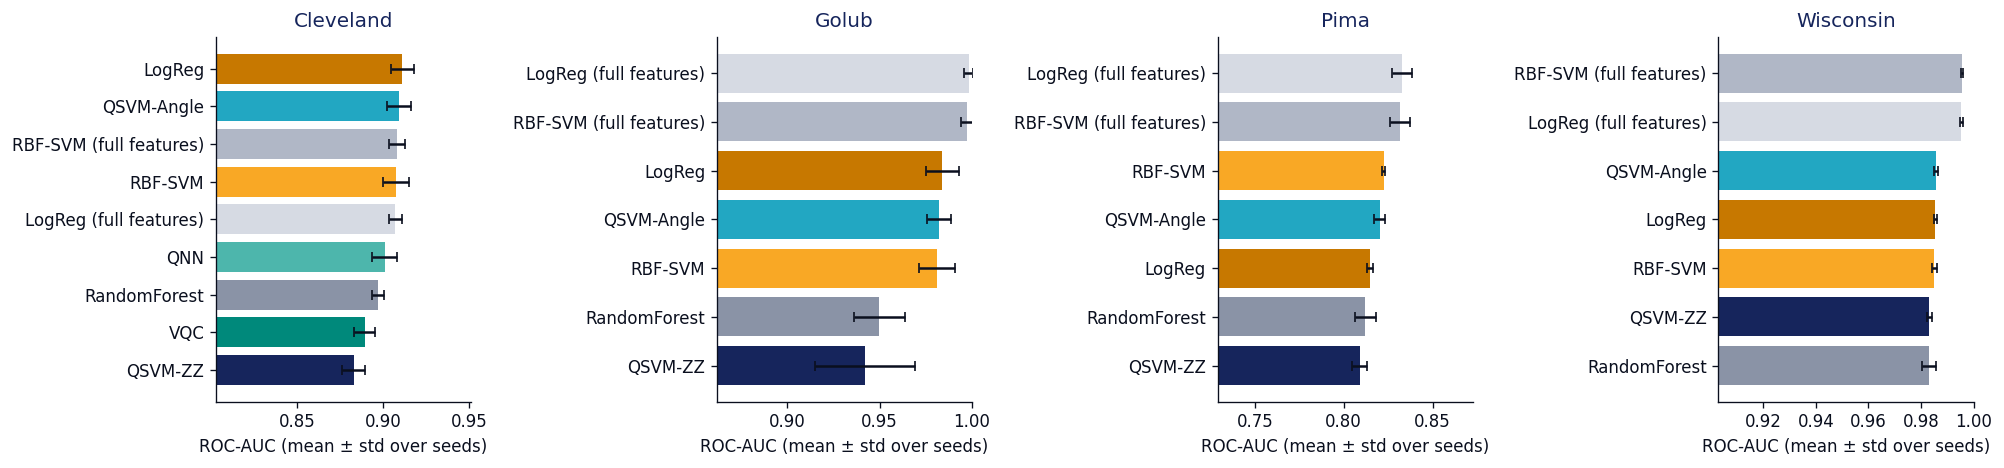

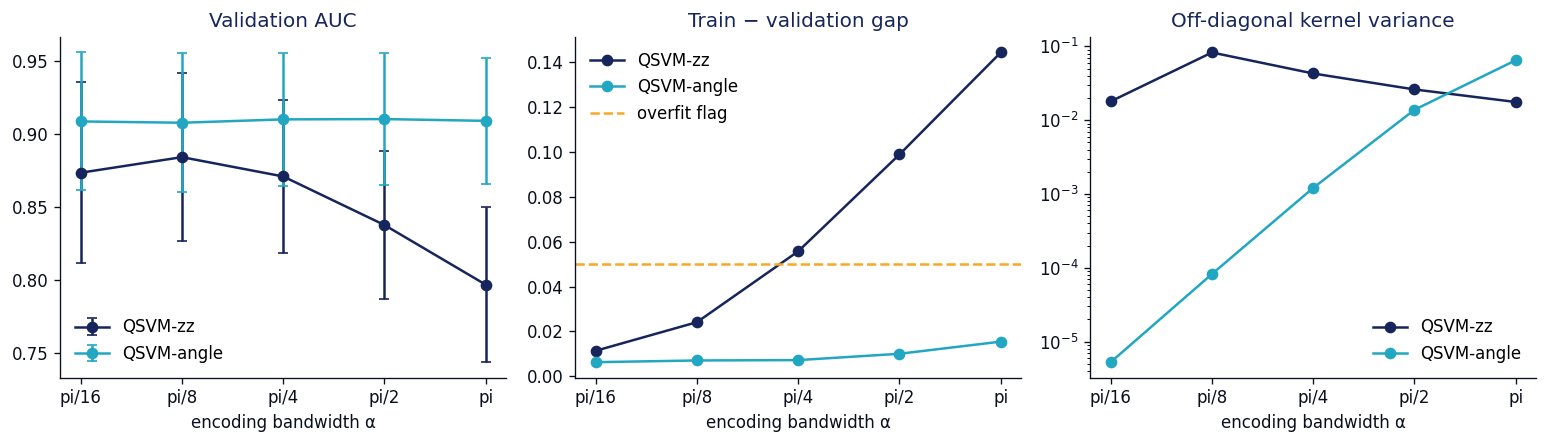

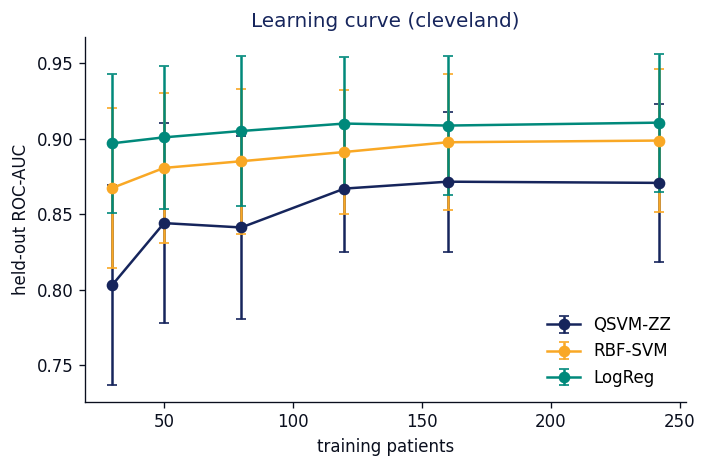

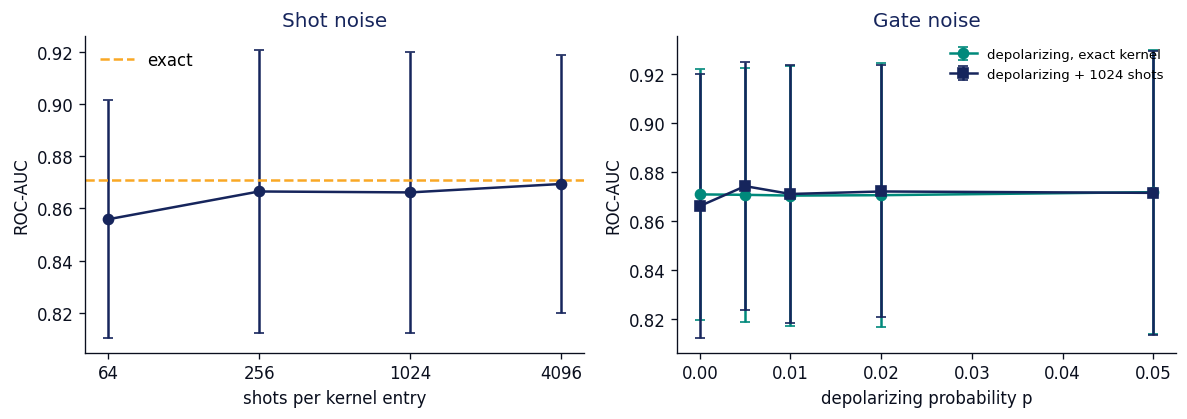

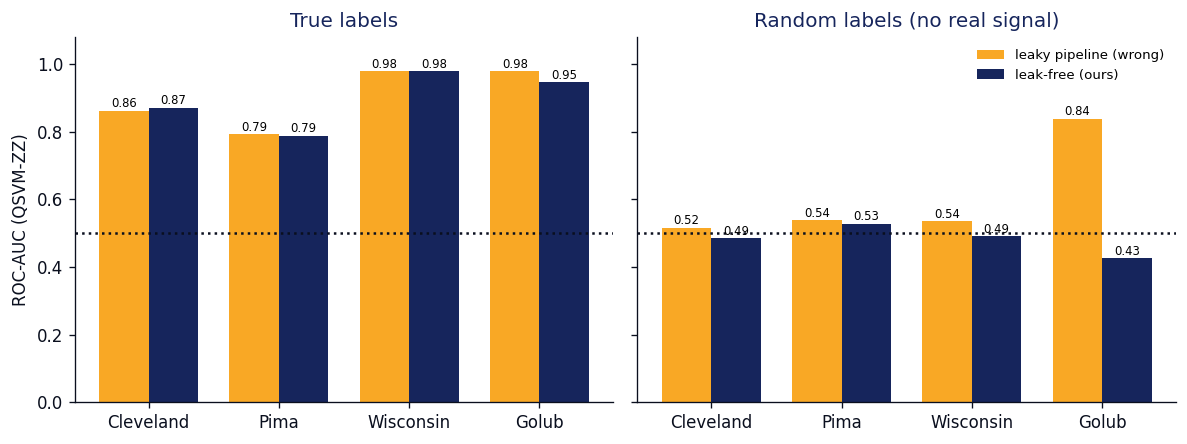

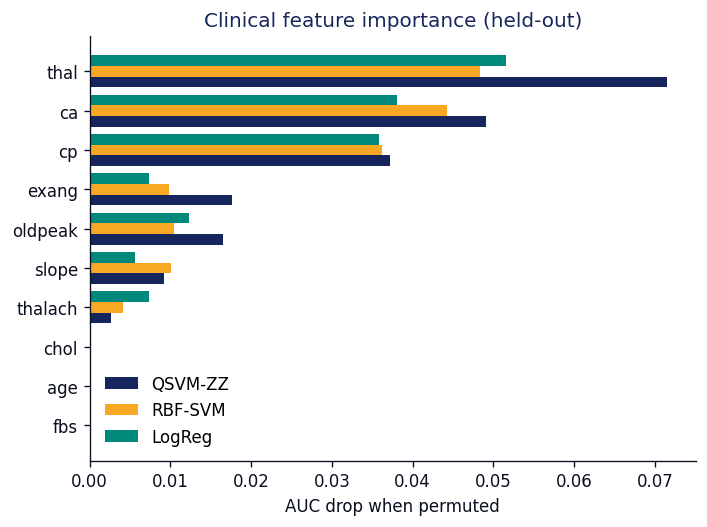

In [22]:
# Figure A: benchmark across datasets
ds_list = list(summary.dataset.unique())
fig, axes = plt.subplots(1, len(ds_list), figsize=(4.2 * len(ds_list), 4), sharey=False)
axes = np.atleast_1d(axes)
for ax, d in zip(axes, ds_list):
    s = summary[summary.dataset == d].sort_values("auc_mean")
    ax.barh(s.model, s.auc_mean, xerr=s.auc_std, color=[MODEL_COLORS.get(m, GREY) for m in s.model],
            ecolor=INK, capsize=3)
    lo = max(0.5, s.auc_mean.min() - 0.08); ax.set_xlim(lo, min(1.0, s.auc_mean.max() + 0.04))
    ax.set_title(d.capitalize(), color=NAVY); ax.set_xlabel("ROC-AUC (mean ± std over seeds)")
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_benchmark.png", bbox_inches="tight"); plt.show()

# Figure B: bandwidth sweep (AUC, gap, kernel variance)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for kind, col in [("zz", NAVY), ("angle", CYAN)]:
    s = bw_sum[bw_sum.kind == kind]
    axes[0].errorbar(s.alpha, s.auc, yerr=s.auc_std, marker="o", color=col, label=f"QSVM-{kind}", capsize=3)
    axes[1].plot(s.alpha, s.gap, marker="o", color=col, label=f"QSVM-{kind}")
    axes[2].plot(s.alpha, s.k_var, marker="o", color=col, label=f"QSVM-{kind}")
axes[1].axhline(GAP_FLAG, ls="--", color=AMBER, label="overfit flag")
axes[2].set_yscale("log")
for ax, t in zip(axes, ["Validation AUC", "Train − validation gap", "Off-diagonal kernel variance"]):
    ax.set_title(t, color=NAVY); ax.set_xlabel("encoding bandwidth α"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_bandwidth.png", bbox_inches="tight"); plt.show()

# Figure C: learning curve
fig, ax = plt.subplots(figsize=(6, 4))
for mname, col in [("QSVM-ZZ", NAVY), ("RBF-SVM", AMBER), ("LogReg", TEAL)]:
    ax.errorbar(ss_sum.n_train, ss_sum[f"{mname}_mean"], yerr=ss_sum[f"{mname}_std"],
                marker="o", color=col, label=mname, capsize=3)
ax.set_xlabel("training patients"); ax.set_ylabel("held-out ROC-AUC")
ax.set_title(f"Learning curve ({PRIMARY})", color=NAVY); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_learning_curve.png", bbox_inches="tight"); plt.show()

# Figure D: noise
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sh = noise_df[noise_df.type == "shots"]; dp = noise_df[noise_df.type == "depolarizing"]
axes[0].errorbar(sh.level.astype(int).astype(str), sh.auc, yerr=sh["std"], marker="o", color=NAVY, capsize=3)
axes[0].axhline(m0, ls="--", color=AMBER, label="exact"); axes[0].set_xlabel("shots per kernel entry")
axes[1].errorbar(np.r_[0, dp.level.astype(float)], np.r_[m0, dp.auc], yerr=np.r_[s0, dp["std"]],
                 marker="o", color=TEAL, capsize=3, label="depolarizing, exact kernel")
dps = noise_df[noise_df.type == "depolarizing+1024shots"]
if len(sh1k := sh[sh.level == 1024]):
    axes[1].errorbar(np.r_[0, dps.level.astype(float)], np.r_[sh1k.auc.iloc[0], dps.auc],
                     yerr=np.r_[sh1k["std"].iloc[0], dps["std"]], marker="s", color=NAVY,
                     capsize=3, label="depolarizing + 1024 shots")
axes[1].legend(frameon=False, fontsize=8)
axes[1].set_xlabel("depolarizing probability p")
for ax, t in zip(axes, ["Shot noise", "Gate noise"]):
    ax.set_title(t, color=NAVY); ax.set_ylabel("ROC-AUC")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_noise.png", bbox_inches="tight"); plt.show()

# Figure E: leakage demo (true vs random labels)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, lab in zip(axes, ["true labels", "RANDOM labels"]):
    lt = leak[(leak.model == "QSVM-ZZ") & (leak.labels == lab)]
    xs = np.arange(len(lt)); w = 0.38
    ax.bar(xs - w/2, lt.leaky_auc, w, color=AMBER, label="leaky pipeline (wrong)")
    ax.bar(xs + w/2, lt.leak_free_auc, w, color=NAVY, label="leak-free (ours)")
    for x_, v in zip(xs - w/2, lt.leaky_auc): ax.text(x_, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
    for x_, v in zip(xs + w/2, lt.leak_free_auc): ax.text(x_, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
    ax.axhline(0.5, ls=":", color=INK); ax.set_xticks(xs)
    ax.set_xticklabels([d.capitalize() for d in lt.dataset]); ax.set_ylim(0, 1.08)
    ax.set_title("True labels" if lab == "true labels" else "Random labels (no real signal)", color=NAVY)
axes[0].set_ylabel("ROC-AUC (QSVM-ZZ)"); axes[1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_leakage.png", bbox_inches="tight"); plt.show()

# Figure F: importance
fig, ax = plt.subplots(figsize=(6, 4.5))
top = wide.head(10)[::-1]; yy = np.arange(len(top)); h = 0.27
for i, (mname, col) in enumerate([("QSVM-ZZ", NAVY), ("RBF-SVM", AMBER), ("LogReg", TEAL)]):
    ax.barh(yy + (i - 1) * h, top[mname], h, color=col, label=mname)
ax.set_yticks(yy); ax.set_yticklabels(top.index); ax.set_xlabel("AUC drop when permuted")
ax.set_title("Clinical feature importance (held-out)", color=NAVY); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_importance.png", bbox_inches="tight"); plt.show()

## ধাপ ১৬ — Claim Checklist (স্বয়ংক্রিয়)

এই cell result দেখে প্রতিটি দাবি **supported / not supported** বলে। Paper-এ শুধু supported দাবিগুলোই লিখতে হবে। Not supported দাবিগুলো negative result হিসেবে সৎভাবে রিপোর্ট করতে হবে, অথবা বাদ দিতে হবে।

**এই checklist নিজের ইচ্ছামতো বদলানো যাবে না।** Result মনমতো না এলে threshold বদলে দাবি "supported" বানানো p-hacking।

**V2-তে একটি criterion বদলানো হয়েছে, আর সেটা সৎভাবে জানানো দরকার।** C6-এর পুরনো fixed ±0.08 সীমা ছোট n-এর স্বাভাবিক বিস্তার হিসাবে নিত না। এখন random-label AUC-কে একই dataset-এর permutation null distribution-এর (mean ± 2.5 sd) সাথে তুলনা করা হয়। এটা পদ্ধতিগতভাবে সঠিক, কিন্তু যেহেতু প্রথম run দেখার পরে বদলানো, paper-এ এটা উল্লেখ করতে হবে।

**C8 (নতুন):** Leaky pipeline random label থেকে কতটা মিথ্যা signal তৈরি করে। এটা paper-এর methodological অবদানের মূল প্রমাণ।

In [23]:
claims = []
p_st = st[(st.dataset == PRIMARY) & (st.comparison == f"{REFERENCE} vs RBF-SVM")]
if len(p_st):
    r = p_st.iloc[0]
    claims.append(("C1 Equivalence: QSVM-ZZ ≈ RBF-SVM on same 4 features",
                   r.verdict.startswith("equivalent"),
                   f"Δ={r.delta_auc:+.3f}, 95%CI [{r.ci95_low:+.3f},{r.ci95_high:+.3f}], verdict={r.verdict}"))
s_zz = bw_sum[bw_sum.kind == "zz"]
rho, p = stats.spearmanr(s_zz.alpha_val, s_zz.gap)
claims.append(("C2 Bandwidth: larger α → larger train-val gap (ZZ)", rho > 0.8,
               f"Spearman ρ={rho:.2f} over {len(s_zz)} α values"))
# Concentration happens at BOTH extremes (K -> 1 for tiny α, K -> 0 for large α),
# so off-diagonal variance should peak at an interior α, not at either end.
imax = int(np.argmax(s_zz.k_var.values))
claims.append(("C2b Bandwidth: kernel variance peaks at an interior α (concentration at both ends)",
               0 < imax < len(s_zz) - 1,
               f"K_var peaks at α={s_zz.alpha.values[imax]}; values "
               + ", ".join(f"{a}:{v:.4f}" for a, v in zip(s_zz.alpha, s_zz.k_var))))
small = ss_sum.iloc[0]
lo, hi = [float(v) for v in small["ci_vs_LogReg"].strip("[]").split(",")]
claims.append(("C3 Small-sample advantage over LogReg at smallest n", lo > 0,
               f"n={int(small.n_train)}, Δ={small['delta_vs_LogReg']:+.3f}, CI [{lo:+.3f},{hi:+.3f}]"))
sh1024 = noise_df[(noise_df.type == "shots") & (noise_df.level == 1024)]
if len(sh1024):
    drop = m0 - sh1024.auc.iloc[0]
    claims.append(("C4 Robust to 1024-shot sampling (AUC drop < 0.02)", drop < 0.02, f"drop={drop:.3f}"))
pf = perm[(perm.dataset == PRIMARY) & (perm.model == "QSVM-ZZ")]
if len(pf):
    claims.append(("C5 Learns real signal (permutation p < 0.05)", pf.p_value.iloc[0] < 0.05,
                   f"p={pf.p_value.iloc[0]:.4f}, shuffled AUC={pf.perm_auc_mean.iloc[0]:.3f}"))
lk = leak[(leak.labels == "RANDOM labels") & (leak.model == "QSVM-ZZ")]
if len(lk):
    # v2 criterion (revised after the QUICK run, disclosed in the paper): the random-label
    # leak-free AUC must lie inside the permutation-test null distribution of the same
    # dataset (mean +/- 2.5 sd). A fixed +/-0.08 band ignored that the null is much wider
    # at n=72 (Golub sd ~0.09) than at n=569.
    ok, ev = [], []
    for _, r in lk.iterrows():
        nul = perm[(perm.dataset == r.dataset) & (perm.model == "QSVM-ZZ")]
        mu, sd = nul.perm_auc_mean.iloc[0], nul.perm_auc_std.iloc[0]
        inside = abs(r.leak_free_auc - mu) <= 2.5 * sd
        ok.append(inside)
        ev.append(f"{r.dataset}: {r.leak_free_auc:.3f} vs null {mu:.3f}±{sd:.3f}{'' if inside else ' OUTSIDE'}")
    claims.append(("C6 Leak-free: random-label AUC inside permutation null", all(ok), "; ".join(ev)))
    big = lk.sort_values("inflation", ascending=False).iloc[0]
    claims.append(("C8 Leaky pipeline manufactures signal from random labels (inflation > 0.2)",
                   big.inflation > 0.2,
                   f"{big.dataset}: leaky {big.leaky_auc:.3f} vs leak-free {big.leak_free_auc:.3f}"))
qg = gate[(gate.dataset == PRIMARY) & (gate.model == "QSVM-ZZ")]
if len(qg):
    claims.append(("C7 No overfitting flag on primary QSVM-ZZ", not bool(qg.overfit_flag.iloc[0]),
                   f"gap={qg.gap_mean.iloc[0]:.3f}"))

cl = pd.DataFrame(claims, columns=["claim", "supported", "evidence"])
cl.to_csv(f"{RESULTS}/claim_checklist.csv", index=False)
for _, r in cl.iterrows():
    print(("✔ SUPPORTED     " if r.supported else "✘ NOT SUPPORTED ") + r.claim + "\n      " + r.evidence)

✘ NOT SUPPORTED C1 Equivalence: QSVM-ZZ ≈ RBF-SVM on same 4 features
      Δ=-0.024, 95%CI [-0.052,+0.003], verdict=inconclusive
✔ SUPPORTED     C2 Bandwidth: larger α → larger train-val gap (ZZ)
      Spearman ρ=1.00 over 5 α values
✔ SUPPORTED     C2b Bandwidth: kernel variance peaks at an interior α (concentration at both ends)
      K_var peaks at α=pi/8; values pi/16:0.0180, pi/8:0.0826, pi/4:0.0429, pi/2:0.0261, pi:0.0176
✘ NOT SUPPORTED C3 Small-sample advantage over LogReg at smallest n
      n=30, Δ=-0.094, CI [-0.110,-0.077]
✔ SUPPORTED     C4 Robust to 1024-shot sampling (AUC drop < 0.02)
      drop=0.005
✔ SUPPORTED     C5 Learns real signal (permutation p < 0.05)
      p=0.0050, shuffled AUC=0.501
✔ SUPPORTED     C6 Leak-free: random-label AUC inside permutation null
      cleveland: 0.486 vs null 0.501±0.039; pima: 0.528 vs null 0.499±0.031; wisconsin: 0.491 vs null 0.500±0.028; golub: 0.426 vs null 0.495±0.084
✔ SUPPORTED     C8 Leaky pipeline manufactures signal from ra

## ধাপ ১৭ — Paper-এর জন্য Table ও Model save
- `results/table_main.csv` → paper-এর Table 2 (main results)
- `results/` → সব raw fold-level result (reviewer চাইলে supplementary-তে দেওয়ার জন্য)
- `models/` → primary dataset-এ পুরো data দিয়ে train করা final model (Streamlit app-এর জন্য)
- `run_metadata.json` → software version, seed, config। Reproducibility-র জন্য।

In [24]:
import joblib, sklearn, platform
tbl = summary.copy()
fmt = lambda m, s: f"{m:.3f} ± {s:.3f}"
tbl["ROC-AUC"] = [fmt(m, s) for m, s in zip(tbl.auc_mean, tbl.auc_std)]
tbl["Accuracy"] = [fmt(m, s) for m, s in zip(tbl.acc_mean, tbl.acc_std)]
tbl = tbl.rename(columns={"sens_mean": "Sensitivity", "spec_mean": "Specificity",
                          "brier_mean": "Brier", "gap_mean": "Train-val gap"})
tbl = tbl[["dataset", "model", "ROC-AUC", "Accuracy", "Sensitivity", "Specificity", "Brier", "Train-val gap"]]
tbl.round(3).to_csv(f"{RESULTS}/table_main.csv", index=False)
display(tbl.round(3))

os.makedirs("models", exist_ok=True)
X, y, nominal = DATA[PRIMARY]
for name in ["QSVM-ZZ", "RBF-SVM", "LogReg"]:
    final = build_model(name, X, nominal, seed=0).fit(X, y)
    joblib.dump(final, f"models/{PRIMARY}_{name}.joblib")
    print("saved", name, "| chosen C:", getattr(final, "best_params_", "n/a"))

meta = dict(date=time.strftime("%Y-%m-%d %H:%M"), quick=QUICK, seeds=SEEDS, folds=N_FOLDS,
            qubits=N_QUBITS, alpha=float(ANGLE_SCALE), k_best=K_BEST, equiv_margin=EQUIV_MARGIN,
            permutations=N_PERMUTATIONS, var_epochs=VAR_EPOCHS, datasets=list(DATA),
            versions=dict(python=platform.python_version(), pennylane=qml.__version__,
                          sklearn=sklearn.__version__, numpy=np.__version__))
json.dump(meta, open(f"{RESULTS}/run_metadata.json", "w"), indent=2)

,dataset,model,ROC-AUC,Accuracy,Sensitivity,Specificity,Brier,Train-val gap
0,cleveland,LogReg,0.911 ± 0.007,0.838 ± 0.007,0.801,0.869,0.133,0.008
3,cleveland,QSVM-Angle,0.909 ± 0.007,0.843 ± 0.010,0.781,0.895,0.149,0.011
6,cleveland,RBF-SVM (full features),0.908 ± 0.005,0.834 ± 0.012,0.829,0.838,0.159,0.013
5,cleveland,RBF-SVM,0.907 ± 0.008,0.838 ± 0.010,0.800,0.870,0.138,0.014
1,cleveland,LogReg (full features),0.907 ± 0.004,0.838 ± 0.008,0.808,0.862,0.121,0.029
2,cleveland,QNN,0.901 ± 0.007,0.838 ± 0.009,0.796,0.874,0.121,0.027
7,cleveland,RandomForest,0.897 ± 0.003,0.827 ± 0.014,0.785,0.862,0.131,0.091
8,cleveland,VQC,0.889 ± 0.006,0.813 ± 0.016,0.824,0.802,0.140,0.014
4,cleveland,QSVM-ZZ,0.883 ± 0.007,0.809 ± 0.010,0.774,0.839,0.146,0.042
10,golub,LogReg (full features),0.998 ± 0.002,0.983 ± 0.006,0.996,0.960,0.023,0.002


saved QSVM-ZZ | chosen C: {'angles__feature_range': (0.0, 0.7853981633974483), 'model__C': 1.0}
saved RBF-SVM | chosen C: {'model__C': 1.0, 'model__gamma_mult': 0.25}
saved LogReg | chosen C: {'model__C': 10.0}


## ধাপ ১৮ — সব result একসাথে package ও download
এই cell একটি text report আর সব result, figure ও model মিলিয়ে একটি zip বানায়, তারপর নিজে থেকেই download শুরু করে। Review-এর জন্য এই zip-টাই পাঠাবেন।

In [25]:
import glob, zipfile

stamp = time.strftime("%Y%m%d_%H%M")
report_path = f"QMed_v2_run_report_{stamp}.txt"

def section(f, title):
    f.write("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78 + "\n")

with open(report_path, "w", encoding="utf-8") as f:
    f.write(f"QMed journal V2 run report | {time.strftime('%Y-%m-%d %H:%M')}\n")
    meta_file = f"{RESULTS}/run_metadata.json"
    if os.path.exists(meta_file):
        section(f, "RUN METADATA")
        f.write(json.dumps(json.load(open(meta_file)), indent=2) + "\n")
    section(f, "DATASETS LOADED")
    for name, (X_, y_, _) in DATA.items():
        f.write(f"{name:10s} n={len(y_)} features={X_.shape[1]} positive_rate={y_.mean():.3f}\n")
    missing = [d for d in LOADERS if d not in DATA]
    f.write(f"SKIPPED: {missing if missing else 'none'}\n")
    for title, csv in [("CLAIM CHECKLIST", "claim_checklist.csv"), ("MAIN TABLE", "table_main.csv"),
                       ("FULL SUMMARY", "benchmark_summary.csv"), ("STATISTICAL TESTS", "statistical_tests.csv"),
                       ("VALIDITY GATE", "validity_gate.csv"), ("PERMUTATION TEST", "permutation_test.csv"),
                       ("LEAKAGE DEMO", "leakage_demo.csv"), ("NOISE SWEEP", "noise_sweep.csv"),
                       ("PCA LOADINGS", "pca_loadings.csv"),
                       ("IMPORTANCE WITH SELECTION FREQUENCY", "importance_with_selection.csv")]:
        p_ = f"{RESULTS}/{csv}"
        if os.path.exists(p_):
            section(f, title); f.write(pd.read_csv(p_).round(4).to_string(index=False) + "\n")
    section(f, "BANDWIDTH SWEEP (aggregated)"); f.write(bw_sum.round(4).to_string(index=False) + "\n")
    section(f, "SAMPLE-SIZE SWEEP (aggregated)"); f.write(ss_sum.round(4).to_string(index=False) + "\n")
    # Which bandwidth / C the inner CV chose for the final primary-dataset models
    section(f, "HYPERPARAMETERS CHOSEN ON FULL PRIMARY DATA")
    for fp in sorted(glob.glob("models/*.joblib")):
        m_ = joblib.load(fp)
        f.write(f"{os.path.basename(fp)}: {getattr(m_, 'best_params_', 'n/a')}\n")

zip_path = f"QMed_v2_results_{stamp}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(report_path)
    for folder in [RESULTS, FIGS, "models"]:
        for fp in glob.glob(f"{folder}/**/*", recursive=True):
            if os.path.isfile(fp):
                z.write(fp)
print(f"Zip: {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
print(open(report_path, encoding="utf-8").read()[:2500])
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Auto-download unavailable, use the Files panel on the left:", e)

Zip: QMed_v2_results_20261016_2118.zip (1.2 MB)
QMed journal V2 run report | 2026-10-16 21:18

RUN METADATA
{
  "date": "2026-10-16 21:18",
  "quick": false,
  "seeds": [
    0,
    1,
    2,
    3,
    4
  ],
  "folds": 5,
  "qubits": 4,
  "alpha": 0.7853981633974483,
  "k_best": 10,
  "equiv_margin": 0.02,
  "permutations": 200,
  "var_epochs": 150,
  "datasets": [
    "cleveland",
    "pima",
    "wisconsin",
    "golub"
  ],
  "versions": {
    "python": "3.13.16",
    "pennylane": "0.45.1",
    "sklearn": "1.6.1",
    "numpy": "2.1.3"
  }
}

DATASETS LOADED
cleveland  n=303 features=13 positive_rate=0.459
pima       n=768 features=8 positive_rate=0.349
wisconsin  n=569 features=30 positive_rate=0.373
golub      n=72 features=7129 positive_rate=0.653
SKIPPED: none

CLAIM CHECKLIST
                                                                             claim  supported                                                                                                               

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# V-3

Cell 1: BreastMNIST load, pre-registration ও CNN embedding

In [26]:
# ===== V3 Cell 1: BreastMNIST imaging arm (pre-registered) — load and embed =====
!pip install -q medmnist

import json, time, os
import numpy as np, pandas as pd
import torch, torchvision
from torchvision.models import resnet18, ResNet18_Weights

# Pre-registration: written BEFORE any BreastMNIST result exists.
PREREG = dict(
    written_at=time.strftime("%Y-%m-%d %H:%M:%S"),
    dataset="BreastMNIST (MedMNIST v2), all 780 images pooled (train+val+test)",
    positive_class="malignant (official label 0)",
    embedding="ImageNet-pretrained ResNet-18, frozen, 224x224 RGB, global-average-pool -> 512-d",
    embedding_uses_labels=False,
    pipeline="identical to tabular datasets: impute->scale->SelectKBest(f_classif,k=10)->PCA(4)->MinMax(0,alpha)->SMOTE, all inside each fold",
    models="CORE_MODELS, same nested grids (C + bandwidth)",
    protocol="5 seeds x stratified 5-fold CV, same tests (corrected t-test, TOST, Holm)",
    reporting_rule="results are reported in the paper regardless of outcome",
)
os.makedirs(RESULTS, exist_ok=True)
json.dump(PREREG, open(f"{RESULTS}/preregistration_breastmnist.json", "w"), indent=2)
print(json.dumps(PREREG, indent=2))

def load_breastmnist_images():
    from medmnist import BreastMNIST
    imgs, labels = [], []
    for split in ["train", "val", "test"]:
        try:
            ds = BreastMNIST(split=split, download=True, size=224, as_rgb=True)
        except Exception as e:
            print(f"  224px download failed ({e}); falling back to 28px, upsampled")
            ds = BreastMNIST(split=split, download=True, as_rgb=True)
        imgs.append(ds.imgs); labels.append(ds.labels.ravel())
    return np.concatenate(imgs), np.concatenate(labels)

imgs, labels = load_breastmnist_images()
if imgs.ndim == 3:                                   # grayscale -> RGB
    imgs = np.repeat(imgs[..., None], 3, axis=-1)
print("images:", imgs.shape, "| label counts:", np.bincount(labels))

# Frozen feature extractor. No labels are used here, so embedding all images once is leak-free.
device = "cuda" if torch.cuda.is_available() else "cpu"
cnn = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
cnn.fc = torch.nn.Identity()
cnn.eval().to(device)
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

feats = []
with torch.no_grad():
    for i in range(0, len(imgs), 64):
        x = torch.tensor(imgs[i:i + 64], dtype=torch.float32).permute(0, 3, 1, 2).to(device) / 255.0
        if x.shape[-1] != 224:
            x = torch.nn.functional.interpolate(x, size=224, mode="bilinear", align_corners=False)
        feats.append(cnn((x - mean) / std).cpu().numpy())
feats = np.concatenate(feats)

X_bm = pd.DataFrame(feats, columns=[f"cnn_{i}" for i in range(feats.shape[1])])
y_bm = (labels == 0).astype(int)                     # 1 = malignant
DATA["breastmnist"] = (X_bm, y_bm, [])
PLAUSIBLE_AUC_CEILING["breastmnist"] = 0.95
print(f"breastmnist n={len(y_bm)} features={X_bm.shape[1]} positive(malignant)={y_bm.mean():.3f} | device={device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 3.8 MB/s eta 0:00:00
{
  "written_at": "2026-10-16 21:46:38",
  "dataset": "BreastMNIST (MedMNIST v2), all 780 images pooled (train+val+test)",
  "positive_class": "malignant (official label 0)",
  "embedding": "ImageNet-pretrained ResNet-18, frozen, 224x224 RGB, global-average-pool -> 512-d",
  "embedding_uses_labels": false,
  "pipeline": "identical to tabular datasets: impute->scale->SelectKBest(f_classif,k=10)->PCA(4)->MinMax(0,alpha)->SMOTE, all inside each fold",
  "models": "CORE_MODELS, same nested grids (C + bandwidth)",
  "protocol": "5 seeds x stratified 5-fold CV, same tests (corrected t-test, TOST, Holm)",
  "reporting_rule": "results are reported in the paper regardless of outcome"
}


100%|██████████| 30.9M/30.9M [00:42<00:00, 719kB/s]


images: (780, 224, 224, 3) | label counts: [210 570]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 94.1MB/s]


breastmnist n=780 features=512 positive(malignant)=0.269 | device=cpu


Cell 2: BreastMNIST benchmark, statistics, permutation test ও leakage demo

In [27]:
# ===== V3 Cell 2: BreastMNIST benchmark, statistics, validity checks =====
from scipy import stats
from sklearn.model_selection import StratifiedKFold, cross_validate, permutation_test_score
from sklearn.linear_model import LogisticRegression

D = "breastmnist"
BM_CSV = f"{RESULTS}/breastmnist_folds.csv"
bm_done = pd.read_csv(BM_CSV) if os.path.exists(BM_CSV) else pd.DataFrame()
for m in CORE_MODELS:
    if len(bm_done) and ((bm_done.model == m) & bm_done.seed.isin(SEEDS)).sum() == len(SEEDS) * N_FOLDS:
        continue
    df_ = evaluate(m, D)
    bm_done = pd.concat([bm_done[bm_done.model != m] if len(bm_done) else bm_done, df_])
    bm_done.to_csv(BM_CSV, index=False)
bm_folds = bm_done[bm_done.seed.isin(SEEDS)].copy()

per_seed = bm_folds.groupby(["model", "seed"]).mean(numeric_only=True).reset_index()
bm_summary = per_seed.groupby("model").agg(
    auc_mean=("auc", "mean"), auc_std=("auc", "std"), acc_mean=("acc", "mean"),
    sens_mean=("sens", "mean"), spec_mean=("spec", "mean"), brier_mean=("brier", "mean"),
    train_auc_mean=("train_auc", "mean"), gap_mean=("gap", "mean")).reset_index()
bm_summary = bm_summary.sort_values("auc_mean", ascending=False)
bm_summary["overfit_flag"] = bm_summary.gap_mean > GAP_FLAG
bm_summary["leak_suspect"] = bm_summary.auc_mean > PLAUSIBLE_AUC_CEILING[D]
bm_summary.to_csv(f"{RESULTS}/breastmnist_summary.csv", index=False)
display(bm_summary.round(4))

# Statistics (same tests as Step 9; redefined so this cell works after a runtime restart)
def corrected_ttest(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b); J = len(d)
    var = d.var(ddof=1) * (1 / J + n_test / n_train); se = np.sqrt(var) if var > 0 else 1e-12
    t = d.mean() / se
    return d.mean(), se, t, 2 * stats.t.sf(abs(t), J - 1), J - 1
def tost(mean_d, se, df, margin=EQUIV_MARGIN):
    return max(stats.t.sf((mean_d + margin) / se, df), stats.t.cdf((mean_d - margin) / se, df))
def holm(p):
    p = np.asarray(p); o = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for r, i in enumerate(o):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(run, 1.0)
    return adj

n = len(DATA[D][1]); n_test = n / N_FOLDS; n_train = n - n_test
f_ = bm_folds.sort_values(["seed", "fold"]); ref = f_[f_.model == "QSVM-ZZ"]
rows = []
for other in [m for m in CORE_MODELS if m != "QSVM-ZZ"]:
    mm = ref.merge(f_[f_.model == other], on=["seed", "fold"], suffixes=("_q", "_c"))
    md, se, t, p, df1 = corrected_ttest(mm.auc_q, mm.auc_c, n_train, n_test)
    q = stats.t.ppf(.975, df1)
    rows.append(dict(dataset=D, comparison=f"QSVM-ZZ vs {other}", delta_auc=md,
                     ci95_low=md - q * se, ci95_high=md + q * se, p_ttest=p, p_tost=tost(md, se, df1)))
bm_st = pd.DataFrame(rows)
bm_st["p_ttest_holm"] = holm(bm_st.p_ttest); bm_st["p_tost_holm"] = holm(bm_st.p_tost)
bm_st["verdict"] = [("QSVM better" if r.delta_auc > 0 else "QSVM worse") if r.p_ttest_holm < 0.05
                    else (f"equivalent (±{EQUIV_MARGIN})" if r.p_tost_holm < 0.05 else "inconclusive")
                    for r in bm_st.itertuples()]
bm_st.to_csv(f"{RESULTS}/breastmnist_statistical_tests.csv", index=False)
display(bm_st.round(4))

# Validity: permutation test and leakage demo, same settings as Steps 10
X, y, nominal = DATA[D]; cv0 = StratifiedKFold(N_FOLDS, shuffle=True, random_state=0)
bm_perm = []
for name, est in [("QSVM-ZZ", QuantumKernelSVM("zz")), ("LogReg", LogisticRegression(max_iter=2000))]:
    sc, ps, p = permutation_test_score(make_pipeline(est, X, nominal), X, y, cv=cv0, scoring="roc_auc",
                                       n_permutations=N_PERMUTATIONS, random_state=0, n_jobs=1)
    bm_perm.append(dict(dataset=D, model=name, auc=sc, perm_auc_mean=ps.mean(), perm_auc_std=ps.std(), p_value=p))
bm_perm = pd.DataFrame(bm_perm); bm_perm.to_csv(f"{RESULTS}/breastmnist_permutation_test.csv", index=False)
display(bm_perm.round(4))

def _cv_auc(est_fn, Xin, yin, pipe):
    out = []
    for s in SEEDS:
        cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=s)
        est = make_pipeline(est_fn(), X, nominal, s) if pipe else est_fn()
        out.append(cross_validate(est, Xin, yin, cv=cv, scoring="roc_auc")["test_score"].mean())
    return np.mean(out)
y_rand = np.random.default_rng(123).permutation(y)
bm_leak = []
for lab, yy in [("true labels", y), ("RANDOM labels", y_rand)]:
    Z = ImbPipeline(make_feature_steps(X, nominal)[:-1]).fit_transform(X, yy)   # fitted on ALL data = leak
    for mname, fn in [("QSVM-ZZ", lambda: QuantumKernelSVM("zz")),
                      ("LogReg", lambda: LogisticRegression(max_iter=2000))]:
        lk_ = _cv_auc(fn, Z, yy, pipe=False); cl_ = _cv_auc(fn, X, yy, pipe=True)
        bm_leak.append(dict(dataset=D, labels=lab, model=mname, leaky_auc=lk_, leak_free_auc=cl_, inflation=lk_ - cl_))
        print(f"{lab:13s} {mname:8s} leaky {lk_:.3f} | leak-free {cl_:.3f} | inflation {lk_-cl_:+.3f}")
bm_leak = pd.DataFrame(bm_leak); bm_leak.to_csv(f"{RESULTS}/breastmnist_leakage_demo.csv", index=False)

  breastmnist QSVM-ZZ                    seed 0: AUC 0.836  (48s)
  breastmnist QSVM-ZZ                    seed 1: AUC 0.827  (39s)
  breastmnist QSVM-ZZ                    seed 2: AUC 0.841  (26s)
  breastmnist QSVM-ZZ                    seed 3: AUC 0.854  (25s)
  breastmnist QSVM-ZZ                    seed 4: AUC 0.827  (24s)
  breastmnist QSVM-Angle                 seed 0: AUC 0.858  (21s)
  breastmnist QSVM-Angle                 seed 1: AUC 0.828  (22s)
  breastmnist QSVM-Angle                 seed 2: AUC 0.853  (20s)
  breastmnist QSVM-Angle                 seed 3: AUC 0.861  (24s)
  breastmnist QSVM-Angle                 seed 4: AUC 0.846  (19s)
  breastmnist RBF-SVM                    seed 0: AUC 0.856  (13s)
  breastmnist RBF-SVM                    seed 1: AUC 0.822  (13s)
  breastmnist RBF-SVM                    seed 2: AUC 0.852  (13s)
  breastmnist RBF-SVM                    seed 3: AUC 0.858  (13s)
  breastmnist RBF-SVM                    seed 4: AUC 0.841  (13s)
  breastmn

,model,auc_mean,auc_std,acc_mean,sens_mean,spec_mean,brier_mean,train_auc_mean,gap_mean,overfit_flag,leak_suspect
5,RBF-SVM (full features),0.9171,0.0077,0.8869,0.7190,0.9488,0.1305,0.9973,0.0803,True,False
1,LogReg (full features),0.8866,0.0043,0.8515,0.7533,0.8877,0.1122,0.9991,0.1124,True,False
0,LogReg,0.8498,0.0123,0.7705,0.7686,0.7712,0.1689,0.8643,0.0146,False,False
2,QSVM-Angle,0.8493,0.0130,0.7726,0.7724,0.7726,0.1634,0.8645,0.0153,False,False
4,RBF-SVM,0.8458,0.0146,0.7797,0.7590,0.7874,0.1609,0.8673,0.0215,False,False
6,RandomForest,0.8402,0.0107,0.7867,0.7162,0.8126,0.1531,0.9387,0.0985,True,False
3,QSVM-ZZ,0.8370,0.0111,0.7741,0.7419,0.7860,0.1598,0.8671,0.0301,False,False


,dataset,comparison,delta_auc,ci95_low,ci95_high,p_ttest,p_tost,p_ttest_holm,p_tost_holm,verdict
0,breastmnist,QSVM-ZZ vs QSVM-Angle,-0.0123,-0.0322,0.0077,0.2169,0.2162,0.7954,0.8649,inconclusive
1,breastmnist,QSVM-ZZ vs RBF-SVM,-0.0088,-0.0293,0.0117,0.3845,0.1356,0.7954,0.6781,inconclusive
2,breastmnist,QSVM-ZZ vs LogReg,-0.0128,-0.0327,0.0072,0.1989,0.2314,0.7954,0.8649,inconclusive
3,breastmnist,QSVM-ZZ vs RandomForest,-0.0032,-0.0297,0.0233,0.8056,0.1019,0.8056,0.6114,inconclusive
4,breastmnist,QSVM-ZZ vs RBF-SVM (full features),-0.0801,-0.1189,-0.0413,0.0003,0.9981,0.0016,1.0000,QSVM worse
5,breastmnist,QSVM-ZZ vs LogReg (full features),-0.0496,-0.0921,-0.0072,0.0239,0.9186,0.1193,1.0000,inconclusive


,dataset,model,auc,perm_auc_mean,perm_auc_std,p_value
0,breastmnist,QSVM-ZZ,0.8313,0.5015,0.0273,0.005
1,breastmnist,LogReg,0.8586,0.5032,0.0329,0.005


true labels   QSVM-ZZ  leaky 0.823 | leak-free 0.826 | inflation -0.003
true labels   LogReg   leaky 0.865 | leak-free 0.850 | inflation +0.014
RANDOM labels QSVM-ZZ  leaky 0.532 | leak-free 0.518 | inflation +0.014
RANDOM labels LogReg   leaky 0.607 | leak-free 0.512 | inflation +0.095


Cell 3: Geometric difference (5 dataset)

done: cleveland
done: pima
done: wisconsin
done: golub
done: breastmnist


,dataset,alpha,kernel,lam,N,g,sqrtN,g_over_sqrtN,s_C,s_Q,sQ_over_sC
1,breastmnist,pi/4,Angle (classical control),0.01,624.0,3.8829,24.9800,0.1554,36.0009,50.7959,1.4124
4,breastmnist,pi/4,ZZ (quantum),0.01,624.0,12.0348,24.9800,0.4818,36.0009,39.1910,1.0898
13,cleveland,pi/4,Angle (classical control),0.01,242.4,2.8468,15.5692,0.1829,27.4857,45.2074,1.6469
16,cleveland,pi/4,ZZ (quantum),0.01,242.4,11.6446,15.5692,0.7479,27.4857,23.6238,0.8593
25,golub,pi/4,Angle (classical control),0.01,57.6,2.5014,7.5894,0.3296,5.2005,18.0947,4.2381
28,golub,pi/4,ZZ (quantum),0.01,57.6,6.6085,7.5894,0.8709,5.2005,3.5109,0.6729
37,pima,pi/4,Angle (classical control),0.01,614.4,3.8069,24.7871,0.1536,48.2818,65.1151,1.3486
40,pima,pi/4,ZZ (quantum),0.01,614.4,9.6846,24.7871,0.3907,48.2818,51.7412,1.0715
49,wisconsin,pi/4,Angle (classical control),0.01,455.2,3.4141,21.3354,0.1600,12.5288,26.2613,2.1179
52,wisconsin,pi/4,ZZ (quantum),0.01,455.2,10.2721,21.3354,0.4814,12.5288,13.4210,1.0772



Interpretation at lam=1e-2, alpha=pi/4 (ZZ kernel):
  breastmnist  g= 12.03 (sqrt N= 25.0, g/sqrtN=0.48): little geometric room for any advantage
               label bounds vacuous (quantum 6.26, classical 6.00) -> no conclusion from s
  cleveland    g= 11.64 (sqrt N= 15.6, g/sqrtN=0.75): geometry differs enough for an advantage to be POSSIBLE
               label bounds vacuous (quantum 4.86, classical 5.24) -> no conclusion from s
  golub        g=  6.61 (sqrt N=  7.6, g/sqrtN=0.87): geometry differs enough for an advantage to be POSSIBLE
               label bounds vacuous (quantum 1.87, classical 2.28) -> no conclusion from s
  pima         g=  9.68 (sqrt N= 24.8, g/sqrtN=0.39): little geometric room for any advantage
               label bounds vacuous (quantum 7.19, classical 6.95) -> no conclusion from s
  wisconsin    g= 10.27 (sqrt N= 21.3, g/sqrtN=0.48): little geometric room for any advantage
               label bounds vacuous (quantum 3.66, classical 3.54) -> no conclusi

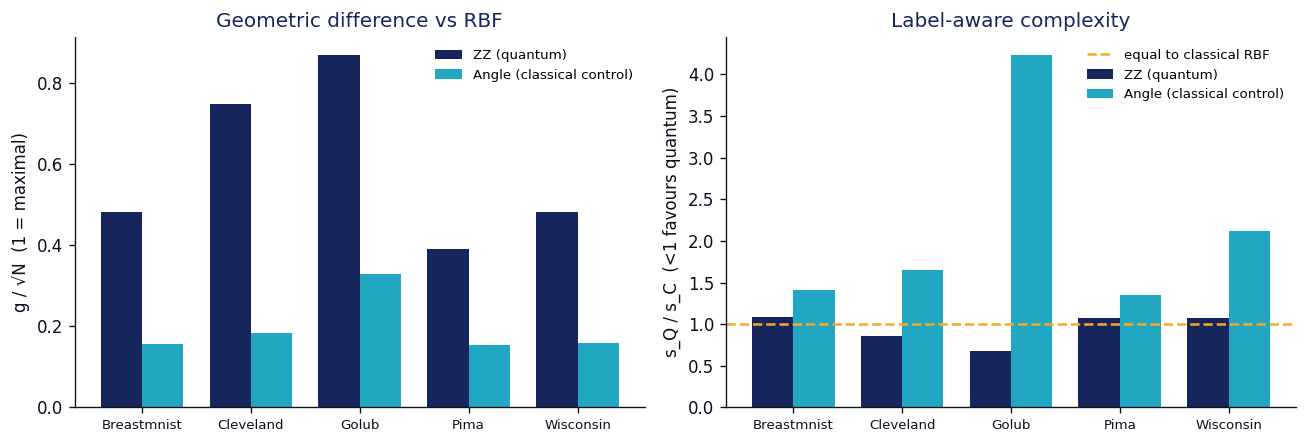

In [28]:
# ===== V3 Cell 3: Could a quantum advantage exist on these datasets at all? =====
# Huang et al. (2021, Nat. Commun.) diagnostics, computed on each TRAINING fold only.
#   g(K_C || K_Q) = sqrt( || sqrt(K_Q) (K_C + lam I)^-1 sqrt(K_Q) ||_inf ),  kernels trace-normalised to N
#     g ~ 1      -> the quantum kernel's geometry is already captured by the classical kernel
#     g ~ sqrt(N)-> geometries differ enough that an advantage is POSSIBLE (not guaranteed)
#   s_K = y^T (K + lam I)^-1 y / N  (label-aware model complexity; lower = easier to learn)
#     generalisation bound ~ sqrt(s_K); a bound >= 1 is VACUOUS (says nothing), so s_Q/s_C is
#     only interpreted when at least one of the two bounds is below 1.
#   The 0.5 threshold on g/sqrt(N) is a heuristic fixed before seeing results, not from Huang et al.
# Control: the angle kernel is classically computable; its g calibrates what a "classical"
# geometric difference from RBF looks like, so the ZZ value can be read against it.
import matplotlib.pyplot as plt

LAMBDAS = [1e-3, 1e-2, 1e-1]           # fixed a priori; lam = 1e-2 is the headline value
HEADLINE_LAM = 1e-2

def _norm(K): return K * len(K) / np.trace(K)
def _sqrt_psd(K):
    w, V = np.linalg.eigh((K + K.T) / 2); return (V * np.sqrt(np.clip(w, 0, None))) @ V.T

def geometric_difference(KC, KQ, lam):
    KC, KQ = _norm(KC), _norm(KQ); S = _sqrt_psd(KQ)
    M = S @ np.linalg.solve(KC + lam * np.eye(len(KC)), S)
    return float(np.sqrt(np.max(np.linalg.eigvalsh((M + M.T) / 2))))

def model_complexity(K, y, lam):
    K = _norm(K); yy = np.where(y == 1, 1.0, -1.0)
    return float(yy @ np.linalg.solve(K + lam * np.eye(len(K)), yy) / len(K))

def rbf_kernel_scale(Z):
    g = 1.0 / (Z.shape[1] * Z.var()); d2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)
    return np.exp(-g * d2)

gd_rows = []
for d in DATA:
    X, y, nominal = DATA[d]
    cv = StratifiedKFold(N_FOLDS, shuffle=True, random_state=0)
    for f, (tr, te) in enumerate(cv.split(X, y)):
        for a_label, a in [("pi/8", np.pi / 8), ("pi/4", np.pi / 4)]:
            Z = ImbPipeline(make_feature_steps(X, nominal, alpha=a)[:-1]).fit(X.iloc[tr], y[tr]).transform(X.iloc[tr])
            KC = rbf_kernel_scale(Z)
            Szz, San = states(Z, "zz"), states(Z, "angle")
            kernels = {"ZZ (quantum)": fidelity_kernel(Szz, Szz),
                       "Angle (classical control)": fidelity_kernel(San, San)}
            for kname, KQ in kernels.items():
                for lam in LAMBDAS:
                    gd_rows.append(dict(dataset=d, alpha=a_label, kernel=kname, lam=lam, fold=f, N=len(tr),
                                        g=geometric_difference(KC, KQ, lam), sqrtN=np.sqrt(len(tr)),
                                        s_C=model_complexity(KC, y[tr], lam),
                                        s_Q=model_complexity(KQ, y[tr], lam)))
    print("done:", d)

gd = pd.DataFrame(gd_rows); gd["g_over_sqrtN"] = gd.g / gd.sqrtN; gd["sQ_over_sC"] = gd.s_Q / gd.s_C
gd.to_csv(f"{RESULTS}/geometric_difference_folds.csv", index=False)
gd_sum = (gd.groupby(["dataset", "alpha", "kernel", "lam"])
            [["N", "g", "sqrtN", "g_over_sqrtN", "s_C", "s_Q", "sQ_over_sC"]].mean().reset_index())
gd_sum.to_csv(f"{RESULTS}/geometric_difference_summary.csv", index=False)
head = gd_sum[(gd_sum.lam == HEADLINE_LAM) & (gd_sum.alpha == "pi/4")]
display(head.round(4))

print("\nInterpretation at lam=1e-2, alpha=pi/4 (ZZ kernel):")
for _, r in head[head.kernel == "ZZ (quantum)"].iterrows():
    room = "geometry differs enough for an advantage to be POSSIBLE" if r.g_over_sqrtN > 0.5 \
        else "little geometric room for any advantage"
    bq, bc = np.sqrt(r.s_Q), np.sqrt(r.s_C)
    if min(bq, bc) >= 1:
        lab = f"label bounds vacuous (quantum {bq:.2f}, classical {bc:.2f}) -> no conclusion from s"
    else:
        lab = f"label bound quantum {bq:.2f} vs classical {bc:.2f} -> " + \
              ("favours quantum" if bq < bc else "favours classical")
    print(f"  {r.dataset:12s} g={r.g:6.2f} (sqrt N={r.sqrtN:5.1f}, g/sqrtN={r.g_over_sqrtN:.2f}): {room}\n"
          f"  {'':12s} {lab}")

# Figure: geometry vs label fit, quantum vs classical control
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ds_ = list(head.dataset.unique()); xs = np.arange(len(ds_)); w = 0.38
for i, (k, col) in enumerate([("ZZ (quantum)", NAVY), ("Angle (classical control)", CYAN)]):
    h = head[head.kernel == k].set_index("dataset").loc[ds_]
    axes[0].bar(xs + (i - 0.5) * w, h.g_over_sqrtN, w, color=col, label=k)
    axes[1].bar(xs + (i - 0.5) * w, h.sQ_over_sC, w, color=col, label=k)
axes[1].axhline(1.0, ls="--", color=AMBER, label="equal to classical RBF")
for ax, t, yl in [(axes[0], "Geometric difference vs RBF", "g / √N  (1 = maximal)"),
                  (axes[1], "Label-aware complexity", "s_Q / s_C  (<1 favours quantum)")]:
    ax.set_xticks(xs); ax.set_xticklabels([d.capitalize() for d in ds_], fontsize=8)
    ax.set_title(t, color=NAVY); ax.set_ylabel(yl); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIGS}/fig_geometric_difference.png", bbox_inches="tight"); plt.show()

Cell 4: All result package and download

In [29]:
# ===== V3 Cell 4: package V3 results for review and download =====
import glob, zipfile
stamp = time.strftime("%Y%m%d_%H%M")
rep = f"QMed_v3_report_{stamp}.txt"
with open(rep, "w", encoding="utf-8") as f:
    f.write(f"QMed V3 report (BreastMNIST + geometric difference) | {time.strftime('%Y-%m-%d %H:%M')}\n")
    f.write(f"quick={QUICK} seeds={SEEDS} permutations={N_PERMUTATIONS}\n")
    for title, csv in [("PRE-REGISTRATION", "preregistration_breastmnist.json"),
                       ("BREASTMNIST SUMMARY", "breastmnist_summary.csv"),
                       ("BREASTMNIST STATISTICAL TESTS", "breastmnist_statistical_tests.csv"),
                       ("BREASTMNIST PERMUTATION TEST", "breastmnist_permutation_test.csv"),
                       ("BREASTMNIST LEAKAGE DEMO", "breastmnist_leakage_demo.csv"),
                       ("GEOMETRIC DIFFERENCE SUMMARY", "geometric_difference_summary.csv")]:
        p_ = f"{RESULTS}/{csv}"
        if not os.path.exists(p_): continue
        f.write("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78 + "\n")
        f.write(open(p_).read() if csv.endswith(".json") else pd.read_csv(p_).round(4).to_string(index=False))
        f.write("\n")
zp = f"QMed_v3_results_{stamp}.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(rep)
    for folder in [RESULTS, FIGS]:
        for fp in glob.glob(f"{folder}/**/*", recursive=True):
            if os.path.isfile(fp): z.write(fp)
print(open(rep, encoding="utf-8").read()[:3000])
try:
    from google.colab import files; files.download(zp)
except Exception as e:
    print("Use the Files panel to download:", zp, e)

QMed V3 report (BreastMNIST + geometric difference) | 2026-10-16 22:06
quick=False seeds=[0, 1, 2, 3, 4] permutations=200

PRE-REGISTRATION
{
  "written_at": "2026-10-16 21:46:38",
  "dataset": "BreastMNIST (MedMNIST v2), all 780 images pooled (train+val+test)",
  "positive_class": "malignant (official label 0)",
  "embedding": "ImageNet-pretrained ResNet-18, frozen, 224x224 RGB, global-average-pool -> 512-d",
  "embedding_uses_labels": false,
  "pipeline": "identical to tabular datasets: impute->scale->SelectKBest(f_classif,k=10)->PCA(4)->MinMax(0,alpha)->SMOTE, all inside each fold",
  "models": "CORE_MODELS, same nested grids (C + bandwidth)",
  "protocol": "5 seeds x stratified 5-fold CV, same tests (corrected t-test, TOST, Holm)",
  "reporting_rule": "results are reported in the paper regardless of outcome"
}

BREASTMNIST SUMMARY
                  model  auc_mean  auc_std  acc_mean  sens_mean  spec_mean  brier_mean  train_auc_mean  gap_mean  overfit_flag  leak_suspect
RBF-SVM (ful

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>